<center>
<img src="../images/fscampus_small2.png" width="1200"/>
</center>

<center>

# Investments

***Finance 2 - BFIN***

**Dr. Omer Cayirli**

Lecturer in Empirical Finance

omer_cayirli@uncbusiness.net
</center>

---

## Lecture 11

---


### Outline

* Derivatives III
  
  * Binomial Option Pricing Model
  
  * Black-Scholes Option Pricing Model

---





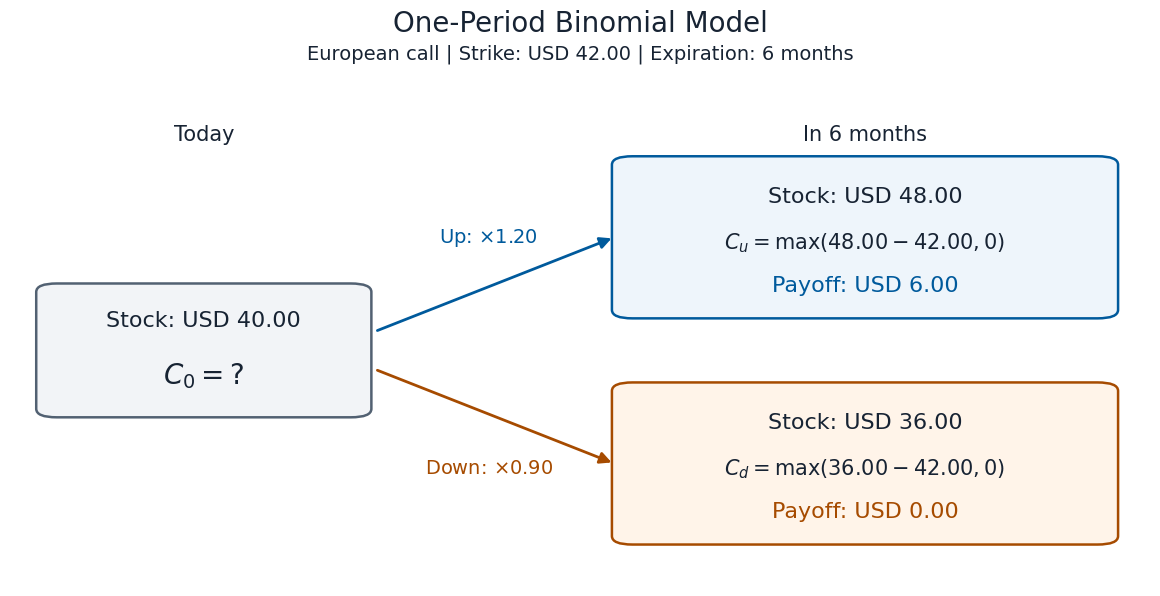

In [ ]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def plot_binomial_payoff(S0, u_price, d_price, K, option_type="Call", T=0.5):
    """Draw a one-period stock tree and its European option payoffs."""
    values = (S0, u_price, d_price, K, T)
    if not all(math.isfinite(value) for value in values):
        raise ValueError("Prices and time to expiration must be finite.")
    if S0 <= 0 or K <= 0 or T <= 0 or d_price < 0 or u_price <= d_price:
        raise ValueError("Require S0 > 0, K > 0, T > 0 and 0 <= d_price < u_price.")
    option_type = option_type.strip().capitalize()
    if option_type not in {"Call", "Put"}:
        raise ValueError("option_type must be 'Call' or 'Put'.")

    symbol = "C" if option_type == "Call" else "P"
    months = 12 * T
    horizon = f"{months:g} month" + ("" if math.isclose(months, 1) else "s")
    ink, up_color, down_color = "#172333", "#005A9C", "#A64B00"

    fig, ax = plt.subplots(figsize=(12, 6.2))
    fig.subplots_adjust(left=0.025, right=0.975, bottom=0.04, top=0.80)
    fig.suptitle("One-Period Binomial Model", fontsize=20, color=ink, y=0.97)
    fig.text(0.5, 0.89,
             f"European {option_type.lower()} | Strike: USD {K:.2f} | Expiration: {horizon}",
             ha="center", fontsize=14, color=ink)
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis("off")

    def box(x, y, width, height, edge, fill):
        patch = FancyBboxPatch(
            (x - width / 2, y - height / 2), width, height,
            boxstyle="round,pad=0.012,rounding_size=0.018",
            edgecolor=edge, facecolor=fill, linewidth=1.8, zorder=2,
        )
        ax.add_patch(patch)

    ax.text(0.17, 0.98, "Today", ha="center", va="top", fontsize=15, color=ink)
    ax.text(0.75, 0.98, f"In {horizon}", ha="center", va="top", fontsize=15, color=ink)
    box(0.17, 0.50, 0.27, 0.26, "#526172", "#F2F4F7")
    ax.text(0.17, 0.55, f"Stock: USD {S0:.2f}", ha="center", fontsize=16, color=ink)
    ax.text(0.17, 0.43, rf"${symbol}_0 = ?$", ha="center", fontsize=20, color=ink)

    for state, stock, y, color, fill in [
        ("Up", u_price, 0.74, up_color, "#EEF5FB"),
        ("Down", d_price, 0.26, down_color, "#FFF4E9"),
    ]:
        start_y = 0.54 if state == "Up" else 0.46
        ax.annotate("", xy=(0.53, y), xytext=(0.32, start_y),
                    arrowprops=dict(arrowstyle="-|>", color=color,
                                    lw=2, mutation_scale=17), zorder=1)
        label_y = 0.73 if state == "Up" else 0.24
        ax.text(0.42, label_y, rf"{state}: $\times {stock / S0:.2f}$",
                ha="center", fontsize=14, color=color)
        box(0.75, y, 0.42, 0.32, color, fill)
        ax.text(0.75, y + 0.075, f"Stock: USD {stock:.2f}",
                ha="center", fontsize=16, color=ink)
        difference = stock - K if option_type == "Call" else K - stock
        payoff = max(difference, 0)
        expression = (f"{stock:.2f}-{K:.2f}" if option_type == "Call"
                      else f"{K:.2f}-{stock:.2f}")
        ax.text(0.75, y - 0.025,
                rf"${symbol}_{{{state[0].lower()}}}=\max({expression},0)$",
                ha="center", fontsize=15, color=ink)
        ax.text(0.75, y - 0.115, f"Payoff: USD {payoff:.2f}",
                ha="center", fontsize=16, color=color)

    plt.show()
    return fig


# Same stock prices, strike and horizon as the following slide.
payoff_tree = plot_binomial_payoff(S0=40, u_price=48, d_price=36, K=42, option_type="Call", T=0.5)


### Binomial Option Pricing Model

*   Asset: Non-dividend-paying stock ($S_0=\$40$).
*   Derivative: Six-month European call ($K=\$42$, $T=0.5$ years).
*   Risk-free rate: $r=6\%$ per year, continuously compounded.

Price Tree

*   Up: $S_u=\$48 \Rightarrow C_u=\max(48-42,0)=\$6$.
*   Down: $S_d=\$36 \Rightarrow C_d=\max(36-42,0)=\$0$.

Risk-Free Portfolio

*   Buy $\Delta$ shares and write one call.
*   Set the terminal portfolio values equal:

$$48\Delta-6=36\Delta
\quad\Rightarrow\quad12\Delta=6
\quad\Rightarrow\quad\Delta=0.5.$$

Valuation by No-Arbitrage

*   The hedge pays the same amount in either state:

$$V_T=48(0.5)-6=36(0.5)=\$18.$$

*   Discount this certain payoff at the risk-free rate:

$$V_0=18e^{-0.06(0.5)}\approx\$17.4680.$$

*   Since $V_0=\Delta S_0-C_0$, the call price is:

$$C_0=\Delta S_0-V_0
=0.5(40)-18e^{-0.06(0.5)}
\approx\$2.5320.$$

---


### Binomial Option Pricing Model: State Prices

**Security paying \$1 in UP state only (Arrow-Debreu Price $P_u$):**
*   Replicate payoff $(1, 0)$ using $\Delta$ stock and $B$ bonds.
    $$
    \begin{cases}
    \text{Up:} & \Delta S_0 u + B r = 1 \\
    \text{Down:} & \Delta S_0 d + B r = 0
    \end{cases}
    \implies
    \begin{cases}
    \Delta = \frac{1}{S_0(u - d)} \\
    B = \frac{-d}{r(u - d)}
    \end{cases}
    $$
*   **Cost ($P_u$):**
    $$ P_u = \Delta S_0 + B = \frac{1}{(u-d)} - \frac{d}{r(u-d)} = \frac{r-d}{r(u-d)} $$

**Security paying \$1 in DOWN state only (Arrow-Debreu Price $P_d$):**
*   Replicate payoff $(0, 1)$.
    $$ P_d = \frac{u-r}{r(u-d)} $$

**General Valuation Formula:**
*   Any derivative with payoffs $f_u, f_d$ can be valued as:
    $$ f = f_u P_u + f_d P_d = \frac{1}{r} \left[ \frac{r-d}{u-d} f_u + \frac{u-r}{u-d} f_d \right] $$

*(Note: $u, d, r$ are gross returns, e.g., $1 + \text{rate}$)*

---



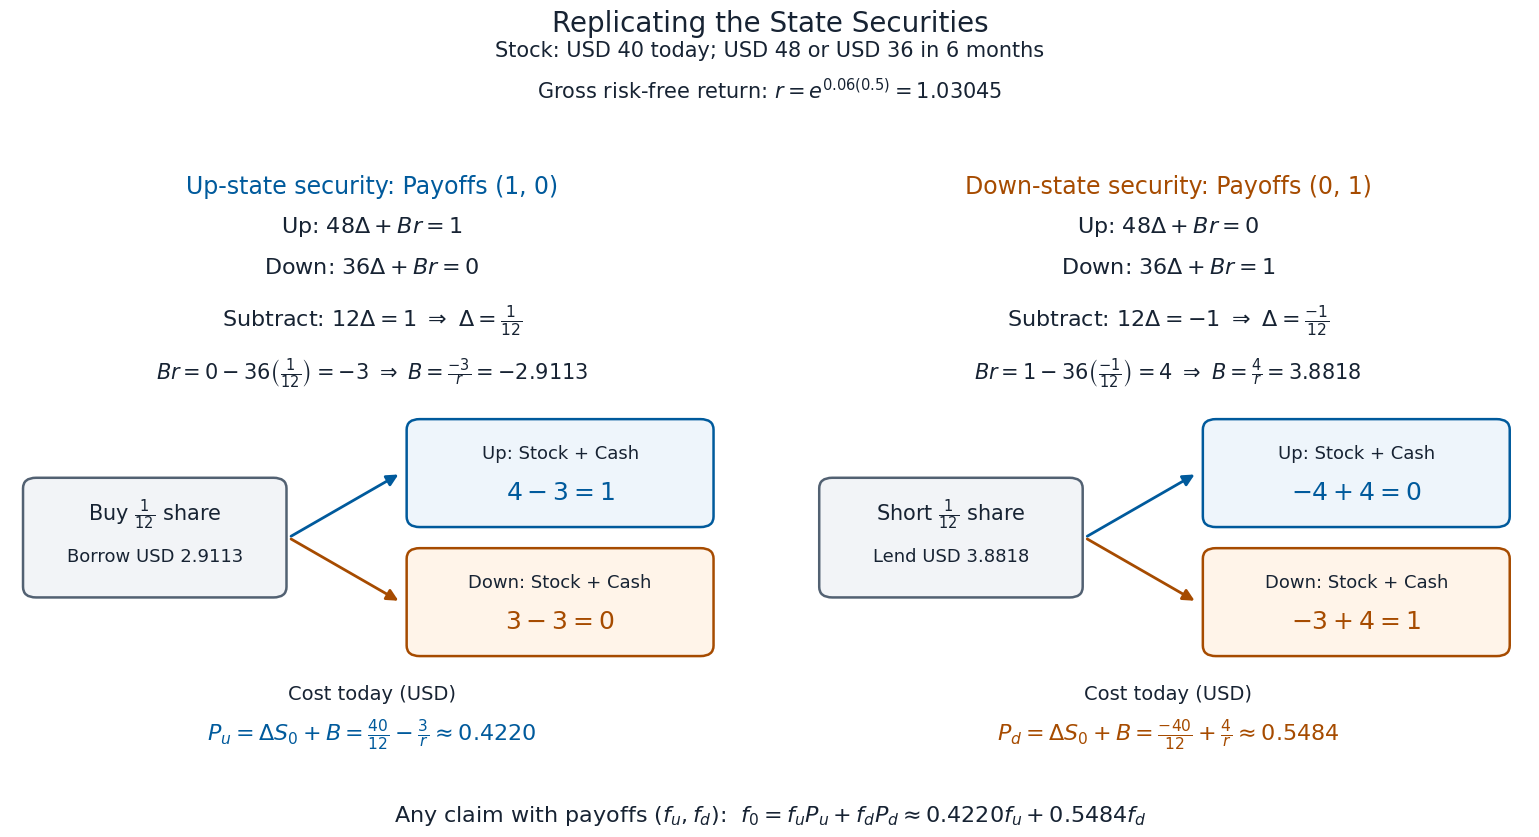

In [ ]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def plot_state_price_replication(S0=40, Su=48, Sd=36, annual_rate=0.06, T=0.5):
    """Replicate the (1, 0) and (0, 1) payoffs using stock and cash."""
    if not all(math.isfinite(x) for x in (S0, Su, Sd, annual_rate, T)):
        raise ValueError("All inputs must be finite.")
    if S0 <= 0 or Sd < 0 or Su <= Sd or T <= 0:
        raise ValueError("Require S0 > 0, 0 <= Sd < Su and T > 0.")
    # Match cell 6: r is the gross risk-free return over the entire period.
    r = math.exp(annual_rate * T)
    if not Sd < S0 * r < Su:
        raise ValueError("No-arbitrage requires Sd < S0 * r < Su.")

    ink, up_color, down_color = "#172333", "#005A9C", "#A64B00"
    gap = Su - Sd
    fig, axes = plt.subplots(1, 2, figsize=(16, 8.5))
    fig.subplots_adjust(left=0.025, right=0.975, top=0.80, bottom=0.11, wspace=0.10)
    fig.suptitle("Replicating the State Securities", fontsize=20, color=ink, y=0.98)
    fig.text(0.5, 0.925,
             f"Stock: USD {S0:g} today; USD {Su:g} or USD {Sd:g} in {12*T:g} months",
             ha="center", fontsize=15, color=ink)
    fig.text(0.5, 0.875,
             rf"Gross risk-free return: $r=e^{{{annual_rate:g}({T:g})}}={r:.5f}$",
             ha="center", fontsize=15, color=ink)
    state_prices = []

    for ax, target, color in zip(axes, ["Up", "Down"], [up_color, down_color]):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")
        fu, fd = (1, 0) if target == "Up" else (0, 1)
        delta = (fu - fd) / gap
        cash_at_T = fd - delta * Sd
        B = cash_at_T / r
        price = delta * S0 + B
        state_prices.append(price)
        suffix = target[0].lower()

        ax.text(0.5, 0.98, f"{target}-state security: Payoffs ({fu}, {fd})",
                ha="center", va="top", fontsize=17, color=color)
        ax.text(0.5, 0.88, rf"Up: ${Su:g}\Delta+Br={fu}$",
                ha="center", fontsize=16, color=ink)
        ax.text(0.5, 0.81, rf"Down: ${Sd:g}\Delta+Br={fd}$",
                ha="center", fontsize=16, color=ink)
        ax.text(0.5, 0.72,
                rf"Subtract: ${gap:g}\Delta={fu-fd:g}"
                rf"\ \Rightarrow\ \Delta=\frac{{{fu-fd:g}}}{{{gap:g}}}$",
                ha="center", fontsize=16, color=ink)
        ax.text(0.5, 0.63,
                rf"$Br={fd}-{Sd:g}\left(\frac{{{fu-fd:g}}}{{{gap:g}}}\right)={cash_at_T:g}"
                rf"\ \Rightarrow\ B=\frac{{{cash_at_T:g}}}{{r}}={B:.4f}$",
                ha="center", fontsize=15, color=ink)

        def box(x, y, width, height, edge, fill):
            ax.add_patch(FancyBboxPatch(
                (x-width/2, y-height/2), width, height,
                boxstyle="round,pad=0.012,rounding_size=0.018",
                facecolor=fill, edgecolor=edge, linewidth=1.8, zorder=2))

        # Positions today branch into their stock-plus-cash payoffs at expiration.
        box(0.20, 0.36, 0.34, 0.18, "#526172", "#F2F4F7")
        stock_action = "Buy" if delta > 0 else "Short"
        cash_action = "Lend" if B > 0 else "Borrow"
        ax.text(0.20, 0.39, rf"{stock_action} $\frac{{1}}{{{gap:g}}}$ share",
                ha="center", fontsize=15, color=ink)
        ax.text(0.20, 0.32, f"{cash_action} USD {abs(B):.4f}",
                ha="center", fontsize=13, color=ink)

        for state, stock, y, edge, fill in [
            ("Up", Su, 0.47, up_color, "#EEF5FB"),
            ("Down", Sd, 0.25, down_color, "#FFF4E9"),
        ]:
            ax.annotate("", xy=(0.54, y), xytext=(0.385, 0.36),
                        arrowprops=dict(arrowstyle="-|>", color=edge,
                                        lw=2, mutation_scale=17), zorder=1)
            box(0.76, y, 0.40, 0.16, edge, fill)
            ax.text(0.76, y+0.025, f"{state}: Stock + Cash",
                    ha="center", fontsize=13, color=ink)
            payoff = delta * stock + cash_at_T
            ax.text(0.76, y-0.045,
                    rf"${delta*stock:g}{cash_at_T:+g}={payoff:g}$",
                    ha="center", fontsize=18, color=edge)

        ax.text(0.5, 0.085, "Cost today (USD)", ha="center", fontsize=14, color=ink)
        ax.text(0.5, 0.015,
                rf"$P_{suffix}=\Delta S_0+B=\frac{{{(fu-fd)*S0:g}}}{{{gap:g}}}"
                rf"{'+' if B >= 0 else '-'}\frac{{{abs(cash_at_T):g}}}{{r}}"
                rf"\approx {price:.4f}$",
                ha="center", fontsize=16, color=color)

    fig.text(0.5, 0.025,
             rf"Any claim with payoffs $(f_u,f_d)$:  $f_0=f_uP_u+f_dP_d"
             rf"\approx {state_prices[0]:.4f}f_u+{state_prices[1]:.4f}f_d$",
             ha="center", fontsize=16, color=ink)
    plt.show()
    return fig


state_price_diagram = plot_state_price_replication()


### Binomial Option Pricing Model
* Note that buying 1 u-security and 1 d-security gives you $1 for certain. Therefore,
$$ P_u + P_d = 1/r \implies \frac{r-d}{r(u-d)} + \frac{u-r}{r(u-d)} = 1/r \implies \underbrace{\frac{r-d}{u-d}}_{p_u} + \underbrace{\frac{u-r}{u-d}}_{p_d} = 1 $$

* The parameters $p_u$ and $p_d$ should be interpreted as the probability of an up and down movement in a risk-neutral world.

* In a risk-neutral world, the expected return on a stock (or any other investment) is the risk-free rate.
$$ E(S_T)=p_uS_0u+(1-p_u)S_0d
=S_0[d+p_u(u-d)]
=S_0[d+(r-d)]
=S_0r. $$

* Risk-neutral valuation provides a very important general result in the pricing of derivatives.
  
  * It states that, when we assume the world is risk-neutral, we get the right price for a derivative in all worlds, not just in a risk-neutral one.
  
  * Results are true regardless of the assumptions we make about the evolution of the stock price.
  
  * To apply risk-neutral valuation to the pricing of a derivative,
  
    * First calculate what the probabilities of different outcomes would be if the world were risk-neutral.
  
    * Then, calculate the expected payoff from the derivative and discount that expected payoff at the risk-free rate of interest.

---



In [1]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def one_period_values(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type):
    """Price a European option using the period's risk-neutral probabilities."""
    if not all(math.isfinite(x) for x in (S0, K, u_pct, d_pct, r_pct, T)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or T <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price, strike and time, and an annual rate above -100%.")
    if option_type not in {"Call", "Put"}:
        raise ValueError("Choose Call or Put.")
    u, d = 1 + u_pct / 100, 1 + d_pct / 100
    if not 0 <= d < u:
        raise ValueError("Require nonnegative down factor and an up factor greater than the down factor.")
    if compounding == "Continuous":
        r = math.exp(r_pct / 100 * T)
    elif compounding == "Annual effective":
        r = (1 + r_pct / 100) ** T
    else:
        raise ValueError("Choose Continuous or Annual effective compounding.")
    # As in the preceding slide, r denotes the gross return over the period.
    if not d < r < u:
        raise ValueError(
            f"No-arbitrage requires d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves, rate or time; no option price is shown.")
    Su, Sd = S0 * u, S0 * d
    sign = 1 if option_type == "Call" else -1
    fu, fd = max(sign * (Su - K), 0), max(sign * (Sd - K), 0)
    p = (r - d) / (u - d)
    expected_payoff = p * fu + (1 - p) * fd
    return dict(u=u, d=d, r=r, Su=Su, Sd=Sd, fu=fu, fd=fd, p=p,
                q=1-p, expected_payoff=expected_payoff, price=expected_payoff/r)


def plot_risk_neutral_tree(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type="Call"):
    m = one_period_values(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type)
    u, d, r, p, q = (m[key] for key in ("u", "d", "r", "p", "q"))
    symbol = "C" if option_type == "Call" else "P"
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    fig, (tree, calc) = plt.subplots(1, 2, figsize=(15, 7),
                                    gridspec_kw={"width_ratios": [1.12, 1]})
    fig.subplots_adjust(left=0.02, right=0.98, top=0.80, bottom=0.14, wspace=0.13)
    fig.suptitle("Risk-Neutral Option Valuation", fontsize=20, color=ink, y=0.97)
    fig.text(0.5, 0.89,
             f"European {option_type.lower()} | Strike: USD {K:.2f} | "
             f"{12*T:g} months | Annual rate: {r_pct:g}% ({compounding.lower()})",
             ha="center", fontsize=14, color=ink)
    # Fixed diagram coordinates preserve the layout across all slider settings.
    for ax in (tree, calc):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")

    def box(x, y, width, height, edge, fill):
        tree.add_patch(FancyBboxPatch(
            (x-width/2, y-height/2), width, height,
            boxstyle="round,pad=0.012,rounding_size=0.018",
            facecolor=fill, edgecolor=edge, linewidth=1.8, zorder=2))

    tree.text(0.19, 0.98, "Today", ha="center", fontsize=14, color=ink)
    tree.text(0.76, 0.98, "At expiration", ha="center", fontsize=14, color=ink)
    box(0.19, 0.50, 0.34, 0.25, "#526172", "#F2F4F7")
    tree.text(0.19, 0.55, f"Stock: USD {S0:.2f}", ha="center", fontsize=15, color=ink)
    tree.text(0.19, 0.43, rf"${symbol}_0={m['price']:.4f}$",
              ha="center", fontsize=18, color=ink)
    for label, stock, payoff, probability, factor, y, color, fill in [
        ("Up", m["Su"], m["fu"], p, u, 0.76, blue, "#EEF5FB"),
        ("Down", m["Sd"], m["fd"], q, d, 0.24, orange, "#FFF4E9"),
    ]:
        tree.annotate("", xy=(0.54, y), xytext=(0.375, 0.54 if label=="Up" else 0.46),
                      arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=17))
        tree.text(0.45, y+0.035 if label=="Up" else y-0.095,
                  rf"$p_{label[0].lower()}={probability:.4f}$",
                  ha="center", fontsize=14, color=color)
        box(0.76, y, 0.40, 0.31, color, fill)
        tree.text(0.76, y+0.085, rf"{label}: $\times {factor:.2f}$",
                  ha="center", fontsize=14, color=color)
        tree.text(0.76, y, f"Stock: USD {stock:.2f}", ha="center", fontsize=15, color=ink)
        tree.text(0.76, y-0.095, f"Payoff: USD {payoff:.2f}", ha="center", fontsize=15, color=color)

    growth = (rf"e^{{{r_pct/100:g}({T:g})}}" if compounding=="Continuous"
              else rf"(1+{r_pct/100:g})^{{{T:g}}}")
    rows = [
        (0.98, "1. Period growth factors", 16),
        (0.89, rf"$u={u:.2f},\quad d={d:.2f},\quad r={growth}={r:.5f}$", 15),
        (0.75, "2. Risk-neutral probabilities", 16),
        (0.64, rf"$p_u=\frac{{r-d}}{{u-d}}=\frac{{{r:.5f}-{d:.2f}}}{{{u:.2f}-{d:.2f}}}={p:.4f}$", 16),
        (0.53, rf"$p_d=1-p_u={q:.4f}$", 15),
        (0.39, "3. Expected payoff and price today", 16),
        (0.29, rf"$E[{symbol}_T]=p_u{symbol}_u+p_d{symbol}_d$", 16),
        (0.20, rf"$={p:.4f}({m['fu']:.2f})+{q:.4f}({m['fd']:.2f})\approx {m['expected_payoff']:.4f}$", 15),
        (0.06, rf"${symbol}_0=\frac{{E[{symbol}_T]}}{{r}}\approx\frac{{{m['expected_payoff']:.4f}}}{{{r:.5f}}}\approx {m['price']:.4f}$", 18),
    ]
    for y, text, size in rows:
        calc.text(0.01, y, text, fontsize=size, color=ink, va="center")
    fig.text(0.5, 0.045,
             rf"Stock check: $E[S_T]={p:.4f}({m['Su']:.2f})+{q:.4f}({m['Sd']:.2f})"
             rf"\approx {S0*r:.4f}=S_0r$",
             ha="center", fontsize=15, color=ink)
    plt.show()
    return fig


def make_risk_neutral_demo():
    style = {"description_width": "125px"}
    def slider(value, low, high, step, label):
        return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                                   description=label, style=style,
                                   layout=widgets.Layout(width="100%"), continuous_update=False)
    controls = {
        "option_type": widgets.Dropdown(options=["Call", "Put"], value="Call",
                                         description="European option:", style=style),
        "compounding": widgets.Dropdown(options=["Continuous", "Annual effective"],
                                         value="Continuous", description="Rate convention:", style=style),
        "S0": slider(40, 10, 100, 1, "Stock (USD):"),
        "K": slider(42, 10, 100, 1, "Strike (USD):"),
        "u_pct": slider(20, 1, 50, 1, "Up move (%):"),
        "d_pct": slider(-10, -50, -1, 1, "Down move (%):"),
        "T": slider(0.5, 0.25, 5, 0.25, "Time (years):"),
        "r_pct": slider(6, 0, 20, 0.5, "Annual rate (%):"),
    }
    grid = widgets.GridBox(list(controls.values()), layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(300px, 1fr))",
        grid_gap="4px 20px", width="100%", max_width="900px"))
    def render(**values):
        try:
            plot_risk_neutral_tree(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output = widgets.interactive_output(render, controls)
    return widgets.VBox([grid, output])


risk_neutral_demo = make_risk_neutral_demo()
display(risk_neutral_demo)


### Binomial Option Pricing Model

*   Derivative: European Call ($K = \$66$, $T = 1$ year)
*   Asset: Stock ($S_0 = \$60$)
*   Dynamics: Stock can rise to $\$78$ or fall to $\$48$.
*   Risk-Free Rate: $4\%$ effective annual

Calculate Parameters ($u, d, r$) and Option Payoffs:
$$ u = 78/60 = 1.30, \quad d = 48/60 = 0.80, \quad r = 1.04 $$
$$
\begin{array}{ll} S_0 = 60 \end{array} \quad \begin{array}{l} \nearrow S_u = 78 \Rightarrow C_u = \max(78-66, 0) = 12 \\ \searrow S_d = 48 \Rightarrow C_d = \max(48-66, 0) = 0 \end{array}
$$

Method A: Replicating Portfolio
$$
\begin{cases}
\text{Up:} & \Delta (78) + B (1.04) = 12 \\
\text{Down:} & \Delta (48) + B (1.04) = 0
\end{cases}
\implies
\begin{cases}
\Delta = \frac{12 - 0}{78 - 48} = 0.40 \\
B = \frac{-0.40 \times 48}{1.04} \approx -18.46
\end{cases}
$$
*   Value: $f = \Delta S_0 + B = 0.40(60) - \frac{19.20}{1.04} \approx \$5.54$

Method B: Risk-Neutral Valuation
$$ p_u = \frac{r - d}{u - d} = \frac{1.04 - 0.80}{1.30 - 0.80} = 0.48 $$
$$ f = \frac{p_u C_u + (1-p_u) C_d}{r} = \frac{0.48(12) + 0.52(0)}{1.04} = \frac{5.76}{1.04} \approx \$5.54 $$

---


In [2]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def example_option_values(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type):
    """Price a European option using the period's risk-neutral probabilities."""
    if not all(math.isfinite(x) for x in (S0, K, u_pct, d_pct, r_pct, T)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or T <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price, strike and time, and an annual rate above -100%.")
    if option_type not in {"Call", "Put"}:
        raise ValueError("Choose Call or Put.")
    u, d = 1 + u_pct / 100, 1 + d_pct / 100
    if not 0 <= d < u:
        raise ValueError("Require nonnegative down factor and an up factor greater than the down factor.")
    if compounding == "Continuous":
        r = math.exp(r_pct / 100 * T)
    elif compounding == "Annual effective":
        r = (1 + r_pct / 100) ** T
    else:
        raise ValueError("Choose Continuous or Annual effective compounding.")
    # As in the preceding slide, r denotes the gross return over the period.
    if not d < r < u:
        raise ValueError(
            f"No-arbitrage requires d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves, rate or time; no option price is shown.")
    Su, Sd = S0 * u, S0 * d
    sign = 1 if option_type == "Call" else -1
    fu, fd = max(sign * (Su - K), 0), max(sign * (Sd - K), 0)
    p = (r - d) / (u - d)
    expected_payoff = p * fu + (1 - p) * fd
    return dict(u=u, d=d, r=r, Su=Su, Sd=Sd, fu=fu, fd=fd, p=p,
                q=1-p, expected_payoff=expected_payoff, price=expected_payoff/r)


def plot_example_option_tree(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type="Call"):
    m = example_option_values(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type)
    u, d, r, p, q = (m[key] for key in ("u", "d", "r", "p", "q"))
    symbol = "C" if option_type == "Call" else "P"
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    fig, (tree, calc) = plt.subplots(1, 2, figsize=(15, 7),
                                    gridspec_kw={"width_ratios": [1.12, 1]})
    fig.subplots_adjust(left=0.02, right=0.98, top=0.80, bottom=0.14, wspace=0.13)
    fig.suptitle("Risk-Neutral Option Valuation", fontsize=20, color=ink, y=0.97)
    fig.text(0.5, 0.89,
             f"European {option_type.lower()} | Strike: USD {K:.2f} | "
             f"{12*T:g} months | Annual rate: {r_pct:g}% ({compounding.lower()})",
             ha="center", fontsize=14, color=ink)
    # Fixed diagram coordinates preserve the layout across all slider settings.
    for ax in (tree, calc):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")

    def box(x, y, width, height, edge, fill):
        tree.add_patch(FancyBboxPatch(
            (x-width/2, y-height/2), width, height,
            boxstyle="round,pad=0.012,rounding_size=0.018",
            facecolor=fill, edgecolor=edge, linewidth=1.8, zorder=2))

    tree.text(0.19, 0.98, "Today", ha="center", fontsize=14, color=ink)
    tree.text(0.76, 0.98, "At expiration", ha="center", fontsize=14, color=ink)
    box(0.19, 0.50, 0.34, 0.25, "#526172", "#F2F4F7")
    tree.text(0.19, 0.55, f"Stock: USD {S0:.2f}", ha="center", fontsize=15, color=ink)
    tree.text(0.19, 0.43, rf"${symbol}_0={m['price']:.4f}$",
              ha="center", fontsize=18, color=ink)
    for label, stock, payoff, probability, factor, y, color, fill in [
        ("Up", m["Su"], m["fu"], p, u, 0.76, blue, "#EEF5FB"),
        ("Down", m["Sd"], m["fd"], q, d, 0.24, orange, "#FFF4E9"),
    ]:
        tree.annotate("", xy=(0.54, y), xytext=(0.375, 0.54 if label=="Up" else 0.46),
                      arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=17))
        tree.text(0.45, y+0.035 if label=="Up" else y-0.095,
                  rf"$p_{label[0].lower()}={probability:.4f}$",
                  ha="center", fontsize=14, color=color)
        box(0.76, y, 0.40, 0.31, color, fill)
        tree.text(0.76, y+0.085, rf"{label}: $\times {factor:.2f}$",
                  ha="center", fontsize=14, color=color)
        tree.text(0.76, y, f"Stock: USD {stock:.2f}", ha="center", fontsize=15, color=ink)
        tree.text(0.76, y-0.095, f"Payoff: USD {payoff:.2f}", ha="center", fontsize=15, color=color)

    growth = (rf"e^{{{r_pct/100:g}({T:g})}}" if compounding=="Continuous"
              else rf"(1+{r_pct/100:g})^{{{T:g}}}")
    rows = [
        (0.98, "1. Period growth factors", 16),
        (0.89, rf"$u={u:.2f},\quad d={d:.2f},\quad r={growth}={r:.5f}$", 15),
        (0.75, "2. Risk-neutral probabilities", 16),
        (0.64, rf"$p_u=\frac{{r-d}}{{u-d}}=\frac{{{r:.5f}-{d:.2f}}}{{{u:.2f}-{d:.2f}}}={p:.4f}$", 16),
        (0.53, rf"$p_d=1-p_u={q:.4f}$", 15),
        (0.39, "3. Expected payoff and price today", 16),
        (0.29, rf"$E[{symbol}_T]=p_u{symbol}_u+p_d{symbol}_d$", 16),
        (0.20, rf"$={p:.4f}({m['fu']:.2f})+{q:.4f}({m['fd']:.2f})\approx {m['expected_payoff']:.4f}$", 15),
        (0.06, rf"${symbol}_0=\frac{{E[{symbol}_T]}}{{r}}\approx\frac{{{m['expected_payoff']:.4f}}}{{{r:.5f}}}\approx {m['price']:.4f}$", 18),
    ]
    for y, text, size in rows:
        calc.text(0.01, y, text, fontsize=size, color=ink, va="center")
    delta = (m["fu"] - m["fd"]) / (m["Su"] - m["Sd"])
    bond = (m["fd"] - delta*m["Sd"]) / r
    fig.text(0.5, 0.045,
             rf"Replication check: $\Delta={delta:.4f},\quad B={bond:.4f},\quad "
             rf"{symbol}_0=\Delta S_0+B={delta:.4f}({S0:.2f})+({bond:.4f})\approx {m['price']:.4f}$",
             ha="center", fontsize=15, color=ink)
    plt.show()
    return fig


def make_example_option_demo():
    style = {"description_width": "125px"}
    def slider(value, low, high, step, label):
        return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                                   description=label, style=style,
                                   layout=widgets.Layout(width="100%"), continuous_update=False)
    controls = {
        "option_type": widgets.Dropdown(options=["Call", "Put"], value="Call",
                                         description="European option:", style=style),
        "compounding": widgets.Dropdown(options=["Continuous", "Annual effective"],
                                         value="Annual effective", description="Rate convention:", style=style),
        "S0": slider(60, 10, 100, 1, "Stock (USD):"),
        "K": slider(66, 10, 100, 1, "Strike (USD):"),
        "u_pct": slider(30, 1, 50, 1, "Up move (%):"),
        "d_pct": slider(-20, -50, -1, 1, "Down move (%):"),
        "T": slider(1, 0.25, 5, 0.25, "Time (years):"),
        "r_pct": slider(4, 0, 20, 0.5, "Annual rate (%):"),
    }
    grid = widgets.GridBox(list(controls.values()), layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(300px, 1fr))",
        grid_gap="4px 20px", width="100%", max_width="900px"))
    def render(**values):
        try:
            plot_example_option_tree(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output = widgets.interactive_output(render, controls)
    return widgets.VBox([grid, output])


example_option_demo = make_example_option_demo()
display(example_option_demo)


### Binomial Option Pricing Model

*   Derivative: European Put ($K = \$52$, $T = 1$ year)
*   Asset: Stock ($S_0 = \$50$)
*   Dynamics: Stock can rise by 20% ($u=1.20$) or fall by 20% ($d=0.80$).
*   Risk-Free Rate: $5\%$ effective annual (gross factor $1.05$)

Calculate Prices and Payoffs:
$$ S_u = 50(1.20) = 60, \quad S_d = 50(0.80) = 40 $$
$$ P_u = \max(52 - 60, 0) = 0 $$
$$ P_d = \max(52 - 40, 0) = 12 $$

Method A: Replicating Portfolio
$$
\begin{cases}
\text{Up:} & \Delta (60) + B (1.05) = 0 \\
\text{Down:} & \Delta (40) + B (1.05) = 12
\end{cases}
\implies
\begin{cases}
\Delta = \frac{0 - 12}{60 - 40} = \frac{-12}{20} = -0.60 \\
B = \frac{0 - (-0.60 \times 60)}{1.05} = \frac{36}{1.05} \approx 34.29
\end{cases}
$$
*   Value: $f = -0.60(50) + \frac{36}{1.05} = -30 + \frac{36}{1.05} \approx \$4.29$

Method B: Risk-Neutral Valuation
$$ p_u = \frac{1.05 - 0.80}{1.20 - 0.80} = \frac{0.25}{0.40} = 0.625 $$
$$ p_d = 1 - 0.625 = 0.375 $$
$$ f = \frac{0.625(0) + 0.375(12)}{1.05} = \frac{4.50}{1.05} \approx \$4.29 $$

---


In [3]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def put_example_values(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type):
    """Price a European option using the period's risk-neutral probabilities."""
    if not all(math.isfinite(x) for x in (S0, K, u_pct, d_pct, r_pct, T)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or T <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price, strike and time, and an annual rate above -100%.")
    if option_type not in {"Call", "Put"}:
        raise ValueError("Choose Call or Put.")
    u, d = 1 + u_pct / 100, 1 + d_pct / 100
    if not 0 <= d < u:
        raise ValueError("Require nonnegative down factor and an up factor greater than the down factor.")
    if compounding == "Continuous":
        r = math.exp(r_pct / 100 * T)
    elif compounding == "Annual effective":
        r = (1 + r_pct / 100) ** T
    else:
        raise ValueError("Choose Continuous or Annual effective compounding.")
    # As in the preceding slide, r denotes the gross return over the period.
    if not d < r < u:
        raise ValueError(
            f"No-arbitrage requires d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves, rate or time; no option price is shown.")
    Su, Sd = S0 * u, S0 * d
    sign = 1 if option_type == "Call" else -1
    fu, fd = max(sign * (Su - K), 0), max(sign * (Sd - K), 0)
    p = (r - d) / (u - d)
    expected_payoff = p * fu + (1 - p) * fd
    return dict(u=u, d=d, r=r, Su=Su, Sd=Sd, fu=fu, fd=fd, p=p,
                q=1-p, expected_payoff=expected_payoff, price=expected_payoff/r)


def plot_put_example_tree(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type="Put"):
    m = put_example_values(S0, K, u_pct, d_pct, r_pct, T, compounding, option_type)
    u, d, r, p, q = (m[key] for key in ("u", "d", "r", "p", "q"))
    symbol = "C" if option_type == "Call" else "P"
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    fig, (tree, calc) = plt.subplots(1, 2, figsize=(15, 7),
                                    gridspec_kw={"width_ratios": [1.12, 1]})
    fig.subplots_adjust(left=0.02, right=0.98, top=0.80, bottom=0.14, wspace=0.13)
    fig.suptitle("Risk-Neutral Option Valuation", fontsize=20, color=ink, y=0.97)
    fig.text(0.5, 0.89,
             f"European {option_type.lower()} | Strike: USD {K:.2f} | "
             f"{12*T:g} months | Annual rate: {r_pct:g}% ({compounding.lower()})",
             ha="center", fontsize=14, color=ink)
    # Fixed diagram coordinates preserve the layout across all slider settings.
    for ax in (tree, calc):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")

    def box(x, y, width, height, edge, fill):
        tree.add_patch(FancyBboxPatch(
            (x-width/2, y-height/2), width, height,
            boxstyle="round,pad=0.012,rounding_size=0.018",
            facecolor=fill, edgecolor=edge, linewidth=1.8, zorder=2))

    tree.text(0.19, 0.98, "Today", ha="center", fontsize=14, color=ink)
    tree.text(0.76, 0.98, "At expiration", ha="center", fontsize=14, color=ink)
    box(0.19, 0.50, 0.34, 0.25, "#526172", "#F2F4F7")
    tree.text(0.19, 0.55, f"Stock: USD {S0:.2f}", ha="center", fontsize=15, color=ink)
    tree.text(0.19, 0.43, rf"${symbol}_0={m['price']:.4f}$",
              ha="center", fontsize=18, color=ink)
    for label, stock, payoff, probability, factor, y, color, fill in [
        ("Up", m["Su"], m["fu"], p, u, 0.76, blue, "#EEF5FB"),
        ("Down", m["Sd"], m["fd"], q, d, 0.24, orange, "#FFF4E9"),
    ]:
        tree.annotate("", xy=(0.54, y), xytext=(0.375, 0.54 if label=="Up" else 0.46),
                      arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=17))
        tree.text(0.45, y+0.035 if label=="Up" else y-0.095,
                  rf"$p_{label[0].lower()}={probability:.4f}$",
                  ha="center", fontsize=14, color=color)
        box(0.76, y, 0.40, 0.31, color, fill)
        tree.text(0.76, y+0.085, rf"{label}: $\times {factor:.2f}$",
                  ha="center", fontsize=14, color=color)
        tree.text(0.76, y, f"Stock: USD {stock:.2f}", ha="center", fontsize=15, color=ink)
        tree.text(0.76, y-0.095, f"Payoff: USD {payoff:.2f}", ha="center", fontsize=15, color=color)

    growth = (rf"e^{{{r_pct/100:g}({T:g})}}" if compounding=="Continuous"
              else rf"(1+{r_pct/100:g})^{{{T:g}}}")
    rows = [
        (0.98, "1. Period growth factors", 16),
        (0.89, rf"$u={u:.2f},\quad d={d:.2f},\quad r={growth}={r:.5f}$", 15),
        (0.75, "2. Risk-neutral probabilities", 16),
        (0.64, rf"$p_u=\frac{{r-d}}{{u-d}}=\frac{{{r:.5f}-{d:.2f}}}{{{u:.2f}-{d:.2f}}}={p:.4f}$", 16),
        (0.53, rf"$p_d=1-p_u={q:.4f}$", 15),
        (0.39, "3. Expected payoff and price today", 16),
        (0.29, rf"$E[{symbol}_T]=p_u{symbol}_u+p_d{symbol}_d$", 16),
        (0.20, rf"$={p:.4f}({m['fu']:.2f})+{q:.4f}({m['fd']:.2f})\approx {m['expected_payoff']:.4f}$", 15),
        (0.06, rf"${symbol}_0=\frac{{E[{symbol}_T]}}{{r}}\approx\frac{{{m['expected_payoff']:.4f}}}{{{r:.5f}}}\approx {m['price']:.4f}$", 18),
    ]
    for y, text, size in rows:
        calc.text(0.01, y, text, fontsize=size, color=ink, va="center")
    delta = (m["fu"] - m["fd"]) / (m["Su"] - m["Sd"])
    bond = (m["fd"] - delta*m["Sd"]) / r
    fig.text(0.5, 0.045,
             rf"Replication check: $\Delta={delta:.4f},\quad B={bond:.4f},\quad "
             rf"{symbol}_0=\Delta S_0+B={delta:.4f}({S0:.2f})+({bond:.4f})\approx {m['price']:.4f}$",
             ha="center", fontsize=15, color=ink)
    plt.show()
    return fig


def make_put_example_demo():
    style = {"description_width": "125px"}
    def slider(value, low, high, step, label):
        return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                                   description=label, style=style,
                                   layout=widgets.Layout(width="100%"), continuous_update=False)
    controls = {
        "option_type": widgets.Dropdown(options=["Call", "Put"], value="Put",
                                         description="European option:", style=style),
        "compounding": widgets.Dropdown(options=["Continuous", "Annual effective"],
                                         value="Annual effective", description="Rate convention:", style=style),
        "S0": slider(50, 10, 100, 1, "Stock (USD):"),
        "K": slider(52, 10, 100, 1, "Strike (USD):"),
        "u_pct": slider(20, 1, 50, 1, "Up move (%):"),
        "d_pct": slider(-20, -50, -1, 1, "Down move (%):"),
        "T": slider(1, 0.25, 5, 0.25, "Time (years):"),
        "r_pct": slider(5, 0, 20, 0.5, "Annual rate (%):"),
    }
    grid = widgets.GridBox(list(controls.values()), layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(300px, 1fr))",
        grid_gap="4px 20px", width="100%", max_width="900px"))
    def render(**values):
        try:
            plot_put_example_tree(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output = widgets.interactive_output(render, controls)
    return widgets.VBox([grid, output])


put_example_demo = make_put_example_demo()
display(put_example_demo)


### Binomial Option Pricing Model

*   Derivative: European Put ($K = \$78$, $T = 1$ year)
*   Asset: Stock ($S_0 = \$80$)
*   Dynamics: Stock can rise by 15% ($u=1.15$) or fall by 10% ($d=0.90$).
*   Risk-Free Rate: $3\%$ effective annual (gross factor $1.03$)

---


### Binomial Option Pricing Model

Calculate Prices and Payoffs:
$$ S_u = 80(1.15) = 92, \quad S_d = 80(0.90) = 72 $$
$$ P_u = \max(78 - 92, 0) = 0 $$
$$ P_d = \max(78 - 72, 0) = 6 $$

Method A: Replicating Portfolio
$$
\begin{cases}
\text{Up:} & \Delta (92) + B (1.03) = 0 \\
\text{Down:} & \Delta (72) + B (1.03) = 6
\end{cases}
\implies
\begin{cases}
\Delta = \frac{0 - 6}{92 - 72} = \frac{-6}{20} = -0.30 \\
B = \frac{0 - (-0.30 \times 92)}{1.03} = \frac{27.60}{1.03} \approx 26.80
\end{cases}
$$
*   Value: $f = -0.30(80) + \frac{27.60}{1.03} = -24 + \frac{27.60}{1.03} \approx \$2.80$

Method B: Risk-Neutral Valuation
$$ p_u = \frac{1.03 - 0.90}{1.15 - 0.90} = \frac{0.13}{0.25} = 0.52 $$
$$ p_d = 1 - 0.52 = 0.48 $$
$$ f = \frac{0.52(0) + 0.48(6)}{1.03} = \frac{2.88}{1.03} \approx \$2.80 $$

---


### Binomial Option Pricing Model: General Formula

* We valued a security paying $1 in the up state and nothing in the down state.

* More generally, consider payoffs $f_u$ in the up state and $f_d$ in the down state.

* Replication: $\Delta$ shares + $B$ invested at the risk-free rate (negative $B$: borrowing).
* $r$: Gross risk-free factor over the period; no-arbitrage requires $d<r<u$.
$$
\begin{cases}
\text{Up:} & \Delta S_0 u + B r = f_u \\
\text{Down:} & \Delta S_0 d + B r = f_d
\end{cases}
\quad \implies \quad
\begin{cases}
\Delta = \frac{f_u - f_d}{S_0(u - d)} \\
B = \frac{u f_d - d f_u}{r(u - d)}
\end{cases}
$$

* Option Price ($f_0$):
    $$ f_0 = \Delta S_0 + B = \frac{1}{r} \left[ \frac{r-d}{u-d} f_u + \frac{u-r}{u-d} f_d \right] $$

**Example: European Put**
* Parameters: $S_0=80, K=84, u=1.25, d=0.75, r=1.05$.
* Payoffs: $f_u = \max(84-100,0)=0$, $f_d = \max(84-60,0)=24$.

    $$ \Delta = \frac{0 - 24}{80(1.25 - 0.75)} = \frac{-24}{40} = -0.60 $$
    $$ B = \frac{1.25(24) - 0.75(0)}{1.05(0.50)} = \frac{30}{0.525} \approx 57.14 $$

    $$ f_0 = -0.60(80) + \frac{30}{0.525} = -48 + \frac{30}{0.525} \approx \$9.14 $$

---


### Binomial Option Pricing Model

* Gamma stock trades at \$50. Over the next year, its price will either rise by 40% or fall by 40%. The risk-free rate is 8% (EAR).
    
    * (a) What is the value of a one-year at-the-money European put?
    
    * (b) What is the value of a one-year at-the-money European call?
    
    * (c) What is the value of a one-year European put with a strike of \$70?
    
    * (d) If the puts in parts (a) and (c) were American, what would their values be?

---


### Binomial Option Pricing Model

1. European Put (ATM, $K=50$)
$$ f_u = \max(K - S_u, 0) = \max(50 - 70, 0) = 0 $$
$$ f_d = \max(K - S_d, 0) = \max(50 - 30, 0) = 20 $$
$$ P_0 = \frac{1}{r} \left[ \frac{r-d}{u-d} f_u + \frac{u-r}{u-d} f_d \right] = \frac{1}{1.08} \left[ \frac{1.08-0.60}{1.40-0.60}(0) + \frac{1.40-1.08}{1.40-0.60}(20) \right] \approx \$7.41 $$

2. European Call (ATM, $K=50$)
$$ f_u = \max(S_u - K, 0) = \max(70 - 50, 0) = 20 $$
$$ f_d = \max(S_d - K, 0) = \max(30 - 50, 0) = 0 $$
$$ C_0 = \frac{1}{1.08} [ 0.60(20) + 0.40(0) ] \approx \$11.11 $$

3. European Put (Deep ITM, $K=70$)
$$ f_u = \max(70 - 70, 0) = 0, \quad f_d = \max(70 - 30, 0) = 40 $$
$$ P_0 = \frac{1}{1.08} [ 0.60(0) + 0.40(40) ] \approx \$14.81 $$

4. American Puts
* ATM ($K=50$): Intrinsic value $=\max(50-50,0)=0$.
* Deep ITM ($K=70$): Intrinsic value $=\max(70-50,0)=20$.
* American value in this one-period model: Maximum of immediate exercise and continuation.
    * Part (a): $\max(0,7.41)=\$7.41$; hold.
    * Part (c): $\max(20,14.81)=\$20.00$; exercise now.

---


In [4]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def american_put_values(S0, K, u_pct, d_pct, r_pct, T):
    """One-period European and American put values; annual effective rate."""
    if not all(math.isfinite(x) for x in (S0, K, u_pct, d_pct, r_pct, T)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or T <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price, strike and time, and a rate above -100%.")
    u, d = 1 + u_pct/100, 1 + d_pct/100
    r = (1 + r_pct/100)**T
    if not 0 <= d < r < u:
        raise ValueError(
            f"No-arbitrage requires 0 <= d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves, rate or time; no option price is shown.")
    Su, Sd = S0*u, S0*d
    fu, fd = max(K-Su, 0), max(K-Sd, 0)
    p = (r-d)/(u-d)
    european = (p*fu + (1-p)*fd)/r
    intrinsic = max(K-S0, 0)
    american = max(european, intrinsic)
    if math.isclose(intrinsic, european, rel_tol=1e-10, abs_tol=1e-10):
        decision = "Indifferent"
    else:
        decision = "Exercise now" if intrinsic > european else "Hold"
    return dict(u=u, d=d, r=r, Su=Su, Sd=Sd, fu=fu, fd=fd, p=p, q=1-p,
                european=european, intrinsic=intrinsic, american=american, decision=decision)


def plot_american_put_comparison(S0, K, u_pct, d_pct, r_pct, T):
    m = american_put_values(S0, K, u_pct, d_pct, r_pct, T)
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    decision_color = orange if m["decision"] == "Exercise now" else blue
    fig, (tree, calc) = plt.subplots(1, 2, figsize=(15, 7.5),
                                    gridspec_kw={"width_ratios": [1.12, 1]})
    fig.subplots_adjust(left=0.02, right=0.98, top=0.80, bottom=0.17, wspace=0.13)
    fig.suptitle("European and American Puts", fontsize=20, color=ink, y=0.97)
    fig.text(0.5, 0.89,
             f"Strike: USD {K:.2f} | {12*T:g} months | "
             f"Annual effective rate: {r_pct:g}% | One-period model",
             ha="center", fontsize=14, color=ink)
    for ax in (tree, calc):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")

    def box(x, y, width, height, edge, fill):
        tree.add_patch(FancyBboxPatch(
            (x-width/2, y-height/2), width, height,
            boxstyle="round,pad=0.012,rounding_size=0.018",
            facecolor=fill, edgecolor=edge, linewidth=1.8, zorder=2))

    tree.text(0.19, 0.98, "Today", ha="center", fontsize=14, color=ink)
    tree.text(0.76, 0.98, "At expiration (if held)", ha="center", fontsize=14, color=ink)
    box(0.19, 0.50, 0.34, 0.35, "#526172", "#F2F4F7")
    tree.text(0.19, 0.60, f"Stock: USD {S0:.2f}", ha="center", fontsize=15, color=ink)
    tree.text(0.19, 0.49, rf"$P_E={m['european']:.4f}$", ha="center", fontsize=17, color=ink)
    tree.text(0.19, 0.38, rf"$P_A={m['american']:.4f}$", ha="center", fontsize=17, color=decision_color)
    for label, stock, payoff, probability, factor, y, color, fill in [
        ("Up", m["Su"], m["fu"], m["p"], m["u"], 0.76, blue, "#EEF5FB"),
        ("Down", m["Sd"], m["fd"], m["q"], m["d"], 0.24, orange, "#FFF4E9"),
    ]:
        tree.annotate("", xy=(0.54, y), xytext=(0.375, 0.54 if label=="Up" else 0.46),
                      arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=17))
        tree.text(0.45, y+0.035 if label=="Up" else y-0.095,
                  rf"$p_{label[0].lower()}={probability:.4f}$",
                  ha="center", fontsize=14, color=color)
        box(0.76, y, 0.40, 0.31, color, fill)
        tree.text(0.76, y+0.085, rf"{label}: $\times {factor:.2f}$", ha="center", fontsize=14, color=color)
        tree.text(0.76, y, f"Stock: USD {stock:.2f}", ha="center", fontsize=15, color=ink)
        tree.text(0.76, y-0.095, f"Payoff: USD {payoff:.2f}", ha="center", fontsize=15, color=color)

    rows = [
        (0.98, "1. Growth factors and probabilities", 16),
        (0.88, rf"$u={m['u']:.2f},\quad d={m['d']:.2f},\quad r=(1+{r_pct/100:g})^{{{T:g}}}={m['r']:.5f}$", 15),
        (0.75, rf"$p_u=\frac{{r-d}}{{u-d}}={m['p']:.4f},\quad p_d={m['q']:.4f}$", 16),
        (0.60, "2. European put: Continuation value", 16),
        (0.47, rf"$P_E=\frac{{{m['p']:.4f}({m['fu']:.2f})+{m['q']:.4f}({m['fd']:.2f})}}{{{m['r']:.5f}}}\approx {m['european']:.4f}$", 16),
        (0.31, "3. Immediate exercise", 16),
        (0.20, rf"$I=\max({K:.2f}-{S0:.2f},0)={m['intrinsic']:.4f}$", 16),
        (0.05, "4. American put: Choose the larger value", 16),
    ]
    for y, text, size in rows:
        calc.text(0.01, y, text, fontsize=size, color=ink, va="center")
    fig.text(0.5, 0.08,
             rf"$P_A=\max(I,P_E)=\max({m['intrinsic']:.4f},{m['european']:.4f})"
             rf"\approx {m['american']:.4f}$" + f"     |     {m['decision']}",
             ha="center", fontsize=18, color=decision_color)
    plt.show()
    return fig


def make_american_put_demo():
    style = {"description_width": "125px"}
    def slider(value, low, high, step, label):
        return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                                   description=label, style=style,
                                   layout=widgets.Layout(width="100%"), continuous_update=False)
    controls = {
        "strike_ratio": widgets.Dropdown(
            options=[("ATM: K = S0", 1.0), ("Deep ITM: K = 1.4 S0", 1.4)],
            value=1.0, description="Put scenario:", style=style,
            layout=widgets.Layout(width="100%")),
        "S0": slider(50, 10, 100, 1, "Stock (USD):"),
        "u_pct": slider(40, 1, 60, 1, "Up move (%):"),
        "d_pct": slider(-40, -60, -1, 1, "Down move (%):"),
        "T": slider(1, 0.25, 5, 0.25, "Time (years):"),
        "r_pct": slider(8, 0, 20, 0.5, "Annual rate (%):"),
    }
    grid = widgets.GridBox(list(controls.values()), layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(300px, 1fr))",
        grid_gap="4px 20px", width="100%", max_width="900px"))
    def render(strike_ratio, **values):
        try:
            plot_american_put_comparison(K=values["S0"]*strike_ratio, **values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output = widgets.interactive_output(render, controls)
    return widgets.VBox([grid, output])


american_put_demo = make_american_put_demo()
display(american_put_demo)


### Binomial Option Pricing Model: Two Periods

* A 6-month European call has strike $K=\$68$. The stock starts at $S_0=\$64$ and rises or falls by 25% each period.
* Two 3-month periods; risk-free rate 8% nominal annual, compounded quarterly. Period rate: $8\%/4=2\%$; gross factor $r=1.02$.

Price Tree ($u=1.25, d=0.75$):
$$ S_0 = 64 \longrightarrow \begin{cases} S_u = 80 \longrightarrow \begin{cases} S_{uu} = 100 \\ S_{ud} = 60 \end{cases} \\ S_d = 48 \longrightarrow \begin{cases} S_{du} = 60 \\ S_{dd} = 36 \end{cases} \end{cases} $$

Option Payoffs at 6 Months ($K=68$):
$$ C_{uu} = 32, \quad C_{ud} = 0, \quad C_{dd} = 0 $$

Backward Induction:
* Step 1 (Value after 3 months):
    $$ C_u = \frac{1}{1.02} \left[ \frac{1.02-0.75}{1.25-0.75}(32) + 0 \right] = \frac{0.54(32)}{1.02} \approx 16.9412 $$
    $$ C_d = 0 \quad (\text{Both terminal payoffs are zero}) $$

* Step 2 (Value today):
    $$ C_0 = \frac{0.54 C_u + 0.46 C_d}{1.02} = \frac{(0.54)^2(32)}{(1.02)^2} \approx \$8.97 $$

---


In [5]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def two_period_call_values(S0, K, u_pct, d_pct, annual_rate_pct):
    """Two quarterly steps; nominal annual rate compounded quarterly."""
    if not all(math.isfinite(x) for x in (S0, K, u_pct, d_pct, annual_rate_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0:
        raise ValueError("Use a positive stock price and strike.")
    u, d = 1 + u_pct/100, 1 + d_pct/100
    r = 1 + annual_rate_pct/400
    if not 0 < d < r < u:
        raise ValueError(
            f"No-arbitrage requires 0 < d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves or rate; no option price is shown.")
    p = (r-d)/(u-d)
    q = 1-p
    Su, Sd = S0*u, S0*d
    Suu, Sud, Sdd = S0*u*u, S0*u*d, S0*d*d
    Cuu, Cud, Cdd = max(Suu-K,0), max(Sud-K,0), max(Sdd-K,0)
    Cu, Cd = (p*Cuu+q*Cud)/r, (p*Cud+q*Cdd)/r
    C0 = (p*Cu+q*Cd)/r
    return dict(u=u,d=d,r=r,p=p,q=q,Su=Su,Sd=Sd,Suu=Suu,Sud=Sud,Sdd=Sdd,
                Cuu=Cuu,Cud=Cud,Cdd=Cdd,Cu=Cu,Cd=Cd,C0=C0)


def plot_two_period_call(S0, K, u_pct, d_pct, annual_rate_pct):
    m = two_period_call_values(S0, K, u_pct, d_pct, annual_rate_pct)
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    neutral, pale = "#526172", "#F2F4F7"
    fig, (tree, calc) = plt.subplots(1,2,figsize=(17,8),
                                    gridspec_kw={"width_ratios":[1.40,1]})
    fig.subplots_adjust(left=0.02,right=0.98,top=0.79,bottom=0.15,wspace=0.12)
    fig.suptitle("Two-Period Binomial Call Valuation",fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.90,
             f"European call | Strike: USD {K:.2f} | Two 3-month periods | "
             f"Nominal annual rate: {annual_rate_pct:g}% (quarterly compounding)",
             ha="center",fontsize=14,color=ink)
    for ax in (tree,calc):
        ax.set(xlim=(0,1),ylim=(0,1))
        ax.axis("off")
    for x,label in [(0.13,"Today"),(0.49,"3 months"),(0.85,"6 months")]:
        tree.text(x,0.985,label,ha="center",fontsize=15,color=ink)

    # Fixed coordinates and rectangular nodes preserve comparability across sliders.
    positions={"0":(0.13,0.50),"u":(0.49,0.665),"d":(0.49,0.335),
               "uu":(0.85,0.83),"ud":(0.85,0.50),"dd":(0.85,0.17)}
    for start,end,is_up in [("0","u",True),("0","d",False),
                            ("u","uu",True),("u","ud",False),
                            ("d","ud",True),("d","dd",False)]:
        x1,y1=positions[start]; x2,y2=positions[end]
        color=blue if is_up else orange
        tree.annotate("",xy=(x2-0.13,y2),xytext=(x1+0.13,y1),
                      arrowprops=dict(arrowstyle="-|>",color=color,lw=2,mutation_scale=16))
        tree.text((x1+x2)/2,(y1+y2)/2+(0.045 if is_up else -0.045),
                  "$p_u$" if is_up else "$p_d$",ha="center",va="center",
                  fontsize=14,color=color)
    nodes=[("0",S0,m["C0"],neutral,pale),
           ("u",m["Su"],m["Cu"],blue,"#EEF5FB"),
           ("d",m["Sd"],m["Cd"],orange,"#FFF4E9"),
           ("uu",m["Suu"],m["Cuu"],blue,"#EEF5FB"),
           ("ud",m["Sud"],m["Cud"],neutral,pale),
           ("dd",m["Sdd"],m["Cdd"],orange,"#FFF4E9")]
    for name,stock,value,color,fill in nodes:
        x,y=positions[name]
        tree.add_patch(FancyBboxPatch((x-0.115,y-0.105),0.23,0.21,
                       boxstyle="round,pad=0.012,rounding_size=0.018",
                       facecolor=fill,edgecolor=color,linewidth=1.8,zorder=2))
        tree.text(x,y+0.04,f"Stock: {stock:.2f}",ha="center",fontsize=15,color=ink)
        label=(f"Payoff: {value:.2f}" if len(name)==2
               else rf"$C_{{{name}}}={value:.4f}$")
        tree.text(x,y-0.045,label,ha="center",fontsize=16,color=color)

    p,q,r=m['p'],m['q'],m['r']
    rows=[
        (0.98,"1. Period factors and probabilities",16),
        (0.88,rf"$u={m['u']:.2f},\quad d={m['d']:.2f},\quad r=1+\frac{{{annual_rate_pct/100:g}}}{{4}}={r:.4f}$",15),
        (0.75,rf"$p_u=\frac{{r-d}}{{u-d}}={p:.4f},\quad p_d={q:.4f}$",16),
        (0.61,"2. Work back to 3 months",16),
        (0.48,rf"$C_u=\frac{{{p:.4f}({m['Cuu']:.2f})+{q:.4f}({m['Cud']:.2f})}}{{{r:.4f}}}\approx {m['Cu']:.4f}$",16),
        (0.34,rf"$C_d=\frac{{{p:.4f}({m['Cud']:.2f})+{q:.4f}({m['Cdd']:.2f})}}{{{r:.4f}}}\approx {m['Cd']:.4f}$",16),
        (0.20,"3. Work back to today",16),
        (0.06,rf"$C_0=\frac{{{p:.4f}({m['Cu']:.4f})+{q:.4f}({m['Cd']:.4f})}}{{{r:.4f}}}\approx {m['C0']:.4f}$",16),
    ]
    for y,text,size in rows:
        calc.text(0.01,y,text,fontsize=size,color=ink,va="center")
    fig.text(0.5,0.055,
             rf"Terminal-payoff check: $C_0=\frac{{p_u^2 C_{{uu}}+2p_up_d C_{{ud}}+p_d^2 C_{{dd}}}}{{r^2}}\approx {m['C0']:.4f}$",
             ha="center",fontsize=17,color=ink)
    plt.show()
    return fig


def make_two_period_call_demo():
    style={"description_width":"125px"}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,
                                   description=label,style=style,
                                   layout=widgets.Layout(width="100%"),continuous_update=False)
    controls={
        "S0":slider(64,10,120,1,"Stock (USD):"),
        "K":slider(68,10,150,1,"Strike (USD):"),
        "u_pct":slider(25,1,60,1,"Up move (%):"),
        "d_pct":slider(-25,-60,-1,1,"Down move (%):"),
        "annual_rate_pct":slider(8,0,20,0.5,"Annual rate (%):"),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(300px, 1fr))",
        grid_gap="4px 20px",width="100%",max_width="900px"))
    def render(**values):
        try:
            plot_two_period_call(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


two_period_call_demo=make_two_period_call_demo()
display(two_period_call_demo)


### Binomial Option Pricing Model: Two-Year Call (State Prices / Risk-Neutral)

* Delta Corp stock trades at $S_0=\$10$. In each of the next two years, its price rises by $\$3$ or falls by $\$2$. No dividends; annual effective risk-free rate: $4\%$.
* Calculate the price of a two-year European call with strike $K=\$12$.

* Gross risk-free return (per year):
    $$ r = 1.04 $$
* $p_0,p_u,p_d$: Up-move probabilities at the root, up node and down node, respectively.

Price Tree:
$$
S_0 = 10 \longrightarrow
\begin{cases}
S_u = 13 \longrightarrow
\begin{cases}
S_{uu} = 16\\
S_{ud} = 11
\end{cases}\\
S_d = 8 \longrightarrow
\begin{cases}
S_{du} = 11\\
S_{dd} = 6
\end{cases}
\end{cases}
$$

Option Payoffs at $T=2$ ($K=12$):
$$
C_{uu} = (16-12)^+ = 4,\quad
C_{ud} = (11-12)^+ = 0,\quad
C_{du} = (11-12)^+ = 0,\quad
C_{dd} = (6-12)^+ = 0
$$

Step 1: Value at $t=1$ (Node-by-Node Risk-Neutral Probabilities)

* Node $u$ (current stock price $S_u=13$):
    * Gross up and down returns:
        $$
        u_u = \frac{S_{uu}}{S_u}=\frac{16}{13}\approx1.2308,\quad
        d_u = \frac{S_{ud}}{S_u}=\frac{11}{13}\approx0.8462
        $$
    * Risk-neutral probability:
        $$
        p_u=\frac{r-d_u}{u_u-d_u}
        =\frac{1.04-11/13}{16/13-11/13}
        =0.504
        $$
    * Backward induction:
        $$
        C_u=\frac{1}{r}\left[p_u C_{uu}+(1-p_u)C_{ud}\right]
        =\frac{0.504(4)+0.496(0)}{1.04}
        \approx1.9385
        $$

* Node $d$ (current stock price $S_d=8$):
    * Both terminal call payoffs are zero ($C_{du}=C_{dd}=0$), hence:
        $$ C_d=0 $$

Step 2: Value at $t=0$ (Risk-Neutral Probability at the Root)

* Gross up and down returns:
    $$
    u_0=\frac{S_u}{S_0}=\frac{13}{10}=1.30,\quad
    d_0=\frac{S_d}{S_0}=\frac{8}{10}=0.80
    $$
* Risk-neutral probability:
    $$
    p_0=\frac{r-d_0}{u_0-d_0}
    =\frac{1.04-0.80}{1.30-0.80}
    =\frac{0.24}{0.50}=0.48
    $$
* Price today:
    $$
    C_0=\frac{p_0 C_u+(1-p_0)C_d}{r}
    \approx\frac{0.48(1.9385)+0.52(0)}{1.04}
    \approx\$0.89
    $$

---


### Binomial Option Pricing Model: Two-Year Put (State Prices / Risk-Neutral)

* Using the same parameters for Delta Corp, calculate the price of a two-year European put with strike $K=\$12$.

* Gross risk-free return (per year):
    $$ r = 1.04 $$

Price Tree:
$$
S_0 = 10 \longrightarrow
\begin{cases}
S_u = 13 \longrightarrow
\begin{cases}
S_{uu} = 16\\
S_{ud} = 11
\end{cases}\\
S_d = 8 \longrightarrow
\begin{cases}
S_{du} = 11\\
S_{dd} = 6
\end{cases}
\end{cases}
$$

Option Payoffs at $T=2$ ($K=12$):
$$
P_{uu} = (12-16)^+ = 0,\quad
P_{ud} = (12-11)^+ = 1,\quad
P_{du} = (12-11)^+ = 1,\quad
P_{dd} = (12-6)^+ = 6
$$

Step 1: Value at $t=1$ (Node-by-Node Risk-Neutral Probabilities)

* Node $u$ (current stock price $S_u=13$):
    * Gross up and down returns:
        $$
        u_u=\frac{16}{13}\approx1.2308,\quad
        d_u=\frac{11}{13}\approx0.8462
        $$
    * Risk-neutral probability:
        $$
        p_u=\frac{r-d_u}{u_u-d_u}
        =\frac{1.04-11/13}{16/13-11/13}
        =0.504
        $$
    * Backward induction:
        $$
        P_u=\frac{p_u P_{uu}+(1-p_u)P_{ud}}{r}
        =\frac{0.504(0)+0.496(1)}{1.04}
        \approx0.4769
        $$

* Node $d$ (current stock price $S_d=8$):
    * Gross up and down returns:
        $$
        u_d=\frac{S_{du}}{S_d}=\frac{11}{8}=1.3750,\quad
        d_d=\frac{S_{dd}}{S_d}=\frac{6}{8}=0.7500
        $$
    * Risk-neutral probability:
        $$
        p_d=\frac{r-d_d}{u_d-d_d}
        =\frac{1.04-0.75}{1.375-0.75}
        =\frac{0.29}{0.625}=0.464
        $$
    * Backward induction:
        $$
        P_d=\frac{p_d P_{du}+(1-p_d)P_{dd}}{r}
        =\frac{0.464(1)+0.536(6)}{1.04}
        \approx3.5385
        $$

Step 2: Value at $t=0$ (Risk-Neutral Probability at the Root)

* Gross up and down returns:
    $$
    u_0=\frac{13}{10}=1.30,\quad d_0=\frac{8}{10}=0.80
    $$
* Risk-neutral probability:
    $$
    p_0=\frac{r-d_0}{u_0-d_0}
    =\frac{1.04-0.80}{1.30-0.80}
    =0.48
    $$
* Price today:
    $$
    P_0=\frac{p_0 P_u+(1-p_0)P_d}{r}
    \approx\frac{0.48(0.4769)+0.52(3.5385)}{1.04}
    \approx\$1.99
    $$

---


In [6]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def additive_option_values(S0, K, up_amt, down_amt, r_pct, option_type):
    """Two annual additive steps with node-specific risk-neutral probabilities."""
    if not all(math.isfinite(x) for x in (S0, K, up_amt, down_amt, r_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or up_amt <= 0 or down_amt <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price, strike and move amounts, and a rate above -100%.")
    if option_type not in {"Call", "Put"}:
        raise ValueError("Choose Call or Put.")
    Su, Sd = S0+up_amt, S0-down_amt
    Suu, Sud, Sdd = S0+2*up_amt, S0+up_amt-down_amt, S0-2*down_amt
    if Sdd < 0:
        raise ValueError(
            f"The two down moves give a negative stock price ({Sdd:.2f}). "
            "Increase the starting price or reduce the down move; no option price is shown.")
    r = 1+r_pct/100
    nodes = {}
    for label, stock, high, low in [("0",S0,Su,Sd),("u",Su,Suu,Sud),("d",Sd,Sud,Sdd)]:
        u, d = high/stock, low/stock
        if not d < r < u:
            raise ValueError(
                f"No-arbitrage requires d < r < u at every node. At node {label}: "
                f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
                "Adjust the moves or rate; no option price is shown.")
        # Use unrounded stock prices; equivalent to (r-d)/(u-d).
        prob = (r*stock-low)/(high-low)
        nodes[label] = dict(u=u,d=d,p=prob,q=1-prob)
    sign = 1 if option_type=="Call" else -1
    Vuu, Vud, Vdd = (max(sign*(stock-K),0) for stock in (Suu,Sud,Sdd))
    Vu = (nodes['u']['p']*Vuu+nodes['u']['q']*Vud)/r
    Vd = (nodes['d']['p']*Vud+nodes['d']['q']*Vdd)/r
    V0 = (nodes['0']['p']*Vu+nodes['0']['q']*Vd)/r
    return dict(r=r,Su=Su,Sd=Sd,Suu=Suu,Sud=Sud,Sdd=Sdd,
                Vuu=Vuu,Vud=Vud,Vdd=Vdd,Vu=Vu,Vd=Vd,V0=V0,nodes=nodes)


def plot_additive_option_tree(S0, K, up_amt, down_amt, r_pct, option_type):
    m = additive_option_values(S0,K,up_amt,down_amt,r_pct,option_type)
    symbol = "C" if option_type=="Call" else "P"
    ink, blue, orange = "#172333", "#005A9C", "#A64B00"
    neutral, pale = "#526172", "#F2F4F7"
    fig, (tree,calc) = plt.subplots(1,2,figsize=(17,8.5),
                                   gridspec_kw={"width_ratios":[1.40,1]})
    fig.subplots_adjust(left=0.02,right=0.98,top=0.79,bottom=0.15,wspace=0.12)
    fig.suptitle("Two-Year Additive Binomial Model",fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.90,
             f"European {option_type.lower()} | Strike: USD {K:.2f} | "
             f"Annual moves: +USD {up_amt:.2f} / -USD {down_amt:.2f} | "
             f"Annual effective rate: {r_pct:g}%",
             ha="center",fontsize=14,color=ink)
    for ax in (tree,calc):
        ax.set(xlim=(0,1),ylim=(0,1))
        ax.axis("off")
    for x,label in [(0.13,"Today"),(0.49,"1 year"),(0.85,"2 years")]:
        tree.text(x,0.985,label,ha="center",fontsize=15,color=ink)

    # Fixed coordinates and rectangular nodes preserve comparability across sliders.
    positions={"0":(0.13,0.50),"u":(0.49,0.665),"d":(0.49,0.335),
               "uu":(0.85,0.83),"ud":(0.85,0.50),"dd":(0.85,0.17)}
    for start,end,is_up in [("0","u",True),("0","d",False),
                            ("u","uu",True),("u","ud",False),
                            ("d","ud",True),("d","dd",False)]:
        x1,y1=positions[start]; x2,y2=positions[end]
        color=blue if is_up else orange
        tree.annotate("",xy=(x2-0.13,y2),xytext=(x1+0.13,y1),
                      arrowprops=dict(arrowstyle="-|>",color=color,lw=2,mutation_scale=16))
        tree.text((x1+x2)/2,(y1+y2)/2+(0.045 if is_up else -0.085),
                  rf"$p_{{{start}}}$" if is_up else rf"$1-p_{{{start}}}$",ha="center",va="center",
                  fontsize=14,color=color)
    nodes=[("0",S0,m["V0"],neutral,pale),
           ("u",m["Su"],m["Vu"],blue,"#EEF5FB"),
           ("d",m["Sd"],m["Vd"],orange,"#FFF4E9"),
           ("uu",m["Suu"],m["Vuu"],blue,"#EEF5FB"),
           ("ud",m["Sud"],m["Vud"],neutral,pale),
           ("dd",m["Sdd"],m["Vdd"],orange,"#FFF4E9")]
    for name,stock,value,color,fill in nodes:
        x,y=positions[name]
        tree.add_patch(FancyBboxPatch((x-0.115,y-0.105),0.23,0.21,
                       boxstyle="round,pad=0.012,rounding_size=0.018",
                       facecolor=fill,edgecolor=color,linewidth=1.8,zorder=2))
        tree.text(x,y+0.04,f"Stock: {stock:.2f}",ha="center",fontsize=15,color=ink)
        label=(f"Payoff: {value:.2f}" if len(name)==2
               else rf"${symbol}_{{{name}}}={value:.4f}$")
        tree.text(x,y-0.045,label,ha="center",fontsize=16,color=color)


    r=m['r']
    nu,nd,n0=(m['nodes'][key] for key in ('u','d','0'))
    rows=[
        (0.98,"1. Work back to year 1",16),
        (0.87,rf"$u_u={nu['u']:.4f},\quad d_u={nu['d']:.4f},\quad p_u={nu['p']:.4f}$",15),
        (0.73,rf"${symbol}_u=\frac{{{nu['p']:.4f}({m['Vuu']:.2f})+{nu['q']:.4f}({m['Vud']:.2f})}}{{{r:.4f}}}\approx {m['Vu']:.4f}$",16),
        (0.58,rf"$u_d={nd['u']:.4f},\quad d_d={nd['d']:.4f},\quad p_d={nd['p']:.4f}$",15),
        (0.44,rf"${symbol}_d=\frac{{{nd['p']:.4f}({m['Vud']:.2f})+{nd['q']:.4f}({m['Vdd']:.2f})}}{{{r:.4f}}}\approx {m['Vd']:.4f}$",16),
        (0.29,"2. Work back to today",16),
        (0.19,rf"$u_0={n0['u']:.4f},\quad d_0={n0['d']:.4f},\quad p_0={n0['p']:.4f}$",15),
        (0.05,rf"${symbol}_0=\frac{{{n0['p']:.4f}({m['Vu']:.4f})+{n0['q']:.4f}({m['Vd']:.4f})}}{{{r:.4f}}}\approx {m['V0']:.4f}$",16),
    ]
    for y,text,size in rows:
        calc.text(0.01,y,text,fontsize=size,color=ink,va="center")
    fig.text(0.5,0.055,
             rf"At node $i$: Up probability $p_i=\frac{{r-d_i}}{{u_i-d_i}}$, "
             rf"down probability $1-p_i$; gross annual factor $r={r:.4f}$.",
             ha="center",fontsize=17,color=ink)
    plt.show()
    return fig


def make_additive_option_demo():
    style={"description_width":"125px"}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,
                                   description=label,style=style,
                                   layout=widgets.Layout(width="100%"),continuous_update=False)
    controls={
        "option_type":widgets.Dropdown(options=["Call","Put"],value="Call",
                                       description="European option:",style=style),
        "r_pct":slider(4,0,15,0.25,"Annual rate (%):"),
        "S0":slider(10,2,30,0.5,"Stock (USD):"),
        "K":slider(12,1,40,0.5,"Strike (USD):"),
        "up_amt":slider(3,0.5,8,0.25,"Up move (USD):"),
        "down_amt":slider(2,0.5,8,0.25,"Down move (USD):"),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns="repeat(2, minmax(300px, 1fr))",
        grid_gap="4px 20px",width="100%",max_width="900px"))
    def render(**values):
        try:
            plot_additive_option_tree(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


additive_option_demo=make_additive_option_demo()
display(additive_option_demo)


### Binomial Option Pricing Model

* Derivative: 2-year European put with strike $K=\$84$.
* Parameters: Stock starts at $S_0=\$80$, rises or falls by 25% each year; annual effective risk-free rate: $5\%$ (gross factor $r=1.05$).

Price Tree:
$$ S_0 = 80 \longrightarrow \begin{cases} S_u = 100 \longrightarrow \begin{cases} S_{uu} = 125 \\ S_{ud} = 75 \end{cases} \\ S_d = 60 \longrightarrow \begin{cases} S_{du} = 75 \\ S_{dd} = 45 \end{cases} \end{cases} $$

Option Payoffs ($T=2, K=84$):
$$ P_{uu}=0, \quad P_{ud}=9, \quad P_{dd}=39 $$

Backward Induction:
$$ P_1^u = \frac{(1.05 - 0.75)(0) + (1.25 - 1.05)(9)}{1.05(1.25 - 0.75)} \approx 3.4286 $$
$$ P_1^d = \frac{(1.05 - 0.75)(9) + (1.25 - 1.05)(39)}{1.05(1.25 - 0.75)} = 20 $$
$$ P_0 = \frac{(1.05 - 0.75)P_1^u + (1.25 - 1.05)P_1^d}{1.05(1.25 - 0.75)} \approx \frac{0.30(3.4286)+0.20(20)}{0.525} \approx \$9.58 $$

---


### Binomial Option Pricing Model

* Derivative: 2-year American put with strike $K=\$84$.
* Parameters: Stock starts at $S_0=\$80$, rises or falls by 25% each year; annual effective risk-free rate: $5\%$ (gross factor $r=1.05$).

Value Tree with Early Exercise Check:
* At $t=1$, down node ($S=60$): Exercise value $84-60=24$ exceeds continuation value $20$.
* Terminal payoffs shown below apply if the option is held to expiry.
$$
P_0 \approx 11.10 \longrightarrow \begin{cases} P_1^u \approx 3.4286 \longrightarrow \begin{cases} P_{uu} = 0 \\ P_{ud} = 9 \end{cases} \\ P_1^d = 24\ \text{(Exercise)} \longrightarrow \begin{cases} P_{du} = 9 \\ P_{dd} = 39 \end{cases} \end{cases}
$$

Calculations:
$$ p=\frac{1.05-0.75}{1.25-0.75}=0.60,\quad 1-p=0.40 $$
$$ P_1^u = \max\left(0,\frac{0.60(0)+0.40(9)}{1.05}\right) \approx 3.4286\quad\text{(Hold)} $$
$$ P_1^d = \max(24,20)=24\quad\text{(Exercise)} $$
$$ H_0=\frac{0.60P_1^u+0.40P_1^d}{1.05}\approx11.1020\quad\text{(Continuation today)} $$
$$ P_0=\max(84-80,H_0)=\max(4,H_0)\approx\$11.10\quad\text{(Hold)} $$

---


In [7]:
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import ipywidgets as widgets
from IPython.display import display, HTML


def two_year_put_values(S0, K, u_pct, d_pct, r_pct, option_style):
    """European and American puts, two annual periods, no dividends."""
    if not all(math.isfinite(x) for x in (S0,K,u_pct,d_pct,r_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if S0 <= 0 or K <= 0 or r_pct <= -100:
        raise ValueError("Use positive stock price and strike, and a rate above -100%.")
    if option_style not in {"European","American"}:
        raise ValueError("Choose European or American.")
    u,d,r=1+u_pct/100,1+d_pct/100,1+r_pct/100
    if not 0 < d < r < u:
        raise ValueError(
            f"No-arbitrage requires 0 < d < r < u. Current factors: "
            f"d = {d:.4f}, r = {r:.4f}, u = {u:.4f}. "
            "Adjust the moves or rate; no option price is shown.")
    p=(r-d)/(u-d); q=1-p
    stocks={'0':S0,'u':S0*u,'d':S0*d,'uu':S0*u*u,'ud':S0*u*d,'dd':S0*d*d}
    terminal={key:max(K-stocks[key],0) for key in ('uu','ud','dd')}
    nodes={}
    def value_node(key, euro_up, euro_down, amer_up, amer_down):
        intrinsic=max(K-stocks[key],0)
        european=(p*euro_up+q*euro_down)/r
        hold_american=(p*amer_up+q*amer_down)/r
        american=max(intrinsic,hold_american)
        if math.isclose(intrinsic,hold_american,rel_tol=1e-10,abs_tol=1e-10):
            decision='Indifferent'
        else:
            decision='Exercise now' if intrinsic>hold_american else 'Hold'
        return dict(I=intrinsic,E=european,A=american,
                    H=hold_american if option_style=='American' else european,
                    P=american if option_style=='American' else european,
                    decision=decision if option_style=='American' else 'European')
    for key,high,low in [('u','uu','ud'),('d','ud','dd')]:
        nodes[key]=value_node(key,terminal[high],terminal[low],terminal[high],terminal[low])
    nodes['0']=value_node('0',nodes['u']['E'],nodes['d']['E'],nodes['u']['A'],nodes['d']['A'])
    return dict(u=u,d=d,r=r,p=p,q=q,stocks=stocks,terminal=terminal,nodes=nodes,
                european=nodes['0']['E'],american=nodes['0']['A'])


def plot_two_year_put(S0, K, u_pct, d_pct, r_pct, option_style):
    m=two_year_put_values(S0,K,u_pct,d_pct,r_pct,option_style)
    ink,blue,orange='#172333','#005A9C','#A64B00'
    red,neutral='#9B1C31','#526172'
    fig,(tree,calc)=plt.subplots(1,2,figsize=(17,9),gridspec_kw={'width_ratios':[1.40,1]})
    fig.subplots_adjust(left=0.02,right=0.98,top=0.77,bottom=0.18,wspace=0.12)
    fig.suptitle('Two-Year European and American Puts',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.91,
             f'{option_style} put | Strike: USD {K:.2f} | Two one-year periods | '
             f'Annual effective rate: {r_pct:g}%',ha='center',fontsize=14,color=ink)
    fig.text(0.5,0.845,
             rf"$u={m['u']:.2f},\quad d={m['d']:.2f},\quad r={m['r']:.4f},\quad "
             rf"p=\frac{{r-d}}{{u-d}}={m['p']:.4f},\quad 1-p={m['q']:.4f}$",
             ha='center',fontsize=16,color=ink)
    for ax in (tree,calc):
        ax.set(xlim=(0,1),ylim=(0,1)); ax.axis('off')
    for x,label in [(0.13,'Today'),(0.49,'1 year'),(0.85,'2 years')]:
        tree.text(x,0.985,label,ha='center',fontsize=15,color=ink)
    positions={'0':(0.13,0.50),'u':(0.49,0.665),'d':(0.49,0.335),
               'uu':(0.85,0.83),'ud':(0.85,0.50),'dd':(0.85,0.17)}
    dashed=False
    for start,end,is_up in [('0','u',True),('0','d',False),('u','uu',True),
                            ('u','ud',False),('d','ud',True),('d','dd',False)]:
        x1,y1=positions[start]; x2,y2=positions[end]
        hypothetical=(m['nodes']['0']['decision']=='Exercise now' or
                      m['nodes'][start]['decision']=='Exercise now')
        dashed |= hypothetical
        color=blue if is_up else orange
        tree.annotate('',xy=(x2-0.13,y2),xytext=(x1+0.13,y1),arrowprops=dict(
            arrowstyle='-|>',color=color,lw=2,mutation_scale=16,
            linestyle='--' if hypothetical else '-',alpha=0.45 if hypothetical else 1))
        tree.text((x1+x2)/2,(y1+y2)/2+(0.045 if is_up else -0.085),
                  '$p$' if is_up else '$1-p$',ha='center',va='center',fontsize=14,color=color)
    for name,(x,y) in positions.items():
        is_terminal=len(name)==2
        if is_terminal:
            color,fill=neutral,'#F2F4F7'
        else:
            exercise=m['nodes'][name]['decision']=='Exercise now'
            color,fill=(red,'#FFF0F2') if exercise else (blue,'#EEF5FB')
        height=0.21 if is_terminal else 0.25
        tree.add_patch(FancyBboxPatch((x-0.115,y-height/2),0.23,height,
            boxstyle='round,pad=0.012,rounding_size=0.018',facecolor=fill,
            edgecolor=color,linewidth=1.8,zorder=2))
        tree.text(x,y+(0.04 if is_terminal else 0.065),f"Stock: {m['stocks'][name]:.2f}",
                  ha='center',fontsize=15,color=ink)
        if is_terminal:
            tree.text(x,y-0.045,f"Payoff: {m['terminal'][name]:.2f}",ha='center',fontsize=16,color=ink)
        else:
            node=m['nodes'][name]
            tree.text(x,y-0.005,rf"$P_{{{name}}}={node['P']:.4f}$",ha='center',fontsize=16,color=color)
            tree.text(x,y-0.08,node['decision'],ha='center',fontsize=14,color=color)

    # At the root, American continuation uses the already optimized year-1 values.
    p,q,r=m['p'],m['q'],m['r']
    for key,title,top,high,low in [
        ('u','1. Up node at year 1',0.98,m['terminal']['uu'],m['terminal']['ud']),
        ('d','2. Down node at year 1',0.63,m['terminal']['ud'],m['terminal']['dd']),
        ('0','3. Today',0.28,m['nodes']['u']['P'],m['nodes']['d']['P'])]:
        node=m['nodes'][key]
        calc.text(0.01,top,title,fontsize=16,color=ink,va='center')
        calc.text(0.01,top-0.11,
                  rf"$H_{{{key}}}=\frac{{{p:.4f}({high:.4f})+{q:.4f}({low:.4f})}}{{{r:.4f}}}\approx {node['H']:.4f}$",
                  fontsize=16,color=ink,va='center')
        if option_style=='American':
            line=(rf"$P_{{{key}}}=\max({node['I']:.4f},{node['H']:.4f})"
                  rf"\approx {node['P']:.4f}$")
        else:
            line=rf"$P_{{{key}}}=H_{{{key}}}\approx {node['P']:.4f}$"
        calc.text(0.01,top-0.21,line,fontsize=16,
                  color=red if node['decision']=='Exercise now' else blue,va='center')
    fig.text(0.5,0.105,
             rf"$H$: Continuation value; American put: $P=\max(\max(K-S,0),H)$.",
             ha='center',fontsize=16,color=ink)
    fig.text(0.5,0.06,
             f"European today: {m['european']:.4f} | American today: {m['american']:.4f} | "
             f"Early-exercise premium: {m['american']-m['european']:.4f}",
             ha='center',fontsize=15,color=ink)
    if dashed:
        fig.text(0.5,0.02,'Dashed branches: Hypothetical continuation after exercise.',
                 ha='center',fontsize=13,color=neutral)
    plt.show()
    return fig


def make_two_year_put_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,
            description=label,style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'option_style':widgets.Dropdown(options=['European','American'],value='American',
                                       description='Exercise style:',style=style),
        'r_pct':slider(5,0,20,0.5,'Annual rate (%):'),
        'S0':slider(80,20,150,1,'Stock (USD):'),
        'K':slider(84,20,180,1,'Strike (USD):'),
        'u_pct':slider(25,1,60,1,'Up move (%):'),
        'd_pct':slider(-25,-60,-1,1,'Down move (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',
        grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try:
            plot_two_year_put(**values)
        except ValueError as error:
            display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


two_year_put_demo=make_two_year_put_demo()
display(two_year_put_demo)


### Black-Scholes Option Pricing Model
* Key assumptions
  
  * There are no arbitrage opportunities.
  
  * Underlying asset is a traded security, and investors can trade continuously.
  
  * The option to be priced is European.
  
  * Constant volatility, with no jumps. In the corresponding binomial approximation, $u$ and $d$ remain constant across equal-length steps.
  
  * No transaction costs or taxes, securities perfectly divisible, no portfolio restrictions, investors are price-takers.

* Continuous trading assumption
  
  * When markets are open, we can trade as we wish, so it is a good approximation.
  
  * But markets do close, so continuous trading is not ideal.

---





### Black-Scholes Option Pricing Model

**Black-Scholes Price of a Call Option on a Non-Dividend-Paying Stock**
$$ C_t = S_t \times N(d_1) - PV(K) \times N(d_2) $$

$\quad\text{where:} $

$$ PV(K) = Ke^{-r_f(T-t)} $$

$$ d_1 = \frac{\ln(S_t/PV(K))}{\sigma\sqrt{T-t}} + \frac{\sigma\sqrt{T-t}}{2} $$
$$ d_2 = d_1 - \sigma\sqrt{T-t} $$

**Black-Scholes Price of a Put Option on a Non-Dividend-Paying Stock**

$$
P_t = PV(K)[1 - N(d_2)] - S_t[1 - N(d_1)]
$$

**Default Notation**

* $\mathbf{S_t}$ : Value of the underlying asset at date $t$;
* $\mathbf{K}$ : Strike price of the option;
* $\mathbf{r_f}$ : Risk-free rate (annual, continuously compounded);
* $\mathbf{\sigma}$ : Volatility (in annual terms), i.e. squared root of the variance;
* $\mathbf{T}$ : Maturity, so at date $t$, $T - t$ is time to maturity in years.
* $\mathbf{N(d)}$ : The cumulative normal distribution
---



### Black-Scholes Option Pricing Model

**Black-Scholes Price of a Call Option on a Non-Dividend-Paying Stock**
$$ C_t = S_t \times N(d_1) - PV(K) \times N(d_2) \quad \text{where} $$
$$ d_1 = \frac{\ln(S_t/PV(K))}{\sigma\sqrt{T-t}} + \frac{\sigma\sqrt{T-t}}{2} $$
$$ d_2 = d_1 - \sigma\sqrt{T-t} $$

**Black-Scholes Price of a Put Option on a Non-Dividend-Paying Stock**
$$ P_t = PV(K)[1 - N(d_2)] - S_t[1 - N(d_1)] $$

* The value of a call is a weighted difference of the present value of its potential benefits, $S_t$, and the present value of its potential costs $PV(K)$ where the weights $N(d_1)$ and $N(d_1 - \sigma\sqrt{T-t})$ are in $(0, 1)$.

* The value of a put is a weighted difference of the present value of its potential benefits, $PV(K)$, and the present value of its potential costs, $S_t$, where the weights $[1 - N(d_2)]$ and $[1 - N(d_1)]$ are in $(0, 1)$.

$$ C_t = S_t \times \underbrace{N(d_1)}_{\Delta} - \underbrace{PV(K) \times N(d_2)}_{\text{Borrowing}} \implies C_t = \text{Asset Price} \times \text{Delta} + \text{Cash Position} $$

---



### Black-Scholes Option Pricing Model

* The standard normal cumulative distribution $N(d)$
  * $N(d)=\Pr(Z\le d)$ for $Z\sim N(0,1)$: Area under the standard normal curve to the left of $d$.
  * $0<N(d)<1$ for finite $d$; approaches 0 and 1 in the tails.
  * Excel: `=NORM.S.DIST(d,TRUE)`.

$$ d_1 = \frac{\ln(S_t/PV(K))}{\sigma\sqrt{T-t}} + \frac{\sigma\sqrt{T-t}}{2} $$
$$ d_2 = d_1 - \sigma\sqrt{T-t} $$

* Volatility follows the square-root-of-time rule when log returns are uncorrelated and have constant variance.
  * Monthly to annual: $\sigma_a=\sqrt{12}\sigma_m$.
  * Weekly to annual: $\sigma_a=\sqrt{52}\sigma_w$.
  * Daily to annual: $\sigma_a=\sqrt{250}\sigma_d$, using 250 trading days per year.

---


In [8]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display, HTML


def normal_bs_values(S, K, tau, r_pct, sigma_pct):
    """Black-Scholes inputs for positive time and volatility; annual cc rate."""
    if not all(math.isfinite(x) for x in (S,K,tau,r_pct,sigma_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if min(S,K,tau,sigma_pct)<=0:
        raise ValueError("Stock price, strike, time and volatility must be positive.")
    r,sigma=r_pct/100,sigma_pct/100
    pv=K*math.exp(-r*tau)
    gap=sigma*math.sqrt(tau)
    term=(math.log(S/K)+r*tau)/gap
    d1=term+gap/2; d2=d1-gap
    n1,n2=norm.cdf(d1),norm.cdf(d2)
    return dict(pv=pv,gap=gap,term=term,d1=d1,d2=d2,n1=n1,n2=n2,
                call=S*n1-pv*n2,sigma=sigma)


def plot_normal_bs(S, K, tau, r_pct, sigma_pct, shade):
    m=normal_bs_values(S,K,tau,r_pct,sigma_pct)
    if shade not in {'d1','d2'}:
        raise ValueError("Choose N(d1) or N(d2).")
    ink,blue,orange='#172333','#005A9C','#A64B00'
    fig,(curve,calc)=plt.subplots(1,2,figsize=(16,8.5),gridspec_kw={'width_ratios':[1.05,1]})
    fig.subplots_adjust(left=0.065,right=0.98,top=0.80,bottom=0.24,wspace=0.20)
    fig.suptitle('The Standard Normal in Black-Scholes',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.90,
        f'Stock: USD {S:.2f} | Strike: USD {K:.2f} | Time to expiry: {tau:g} years | '
        f'Annual cc rate: {r_pct:g}% | Annual volatility: {sigma_pct:g}%',
        ha='center',fontsize=14,color=ink)
    x=np.linspace(-4,4,1201)
    curve.plot(x,norm.pdf(x),color=ink,lw=2)
    # Fixed axes keep the bell curve comparable, including extreme slider settings.
    curve.set(xlim=(-4,4),ylim=(0,0.46),xlabel='Standard-normal value (z)',ylabel='Probability density')
    curve.tick_params(labelsize=13)
    curve.xaxis.label.set_size(14); curve.yaxis.label.set_size(14)
    curve.spines[['top','right']].set_visible(False)
    value=m[shade]; number=shade[-1]
    color=blue if shade=='d1' else orange
    # Include the boundary exactly instead of rounding the selected area to a grid point.
    if value>-4:
        fill_x=np.linspace(-4,min(value,4),1201)
        curve.fill_between(fill_x,norm.pdf(fill_x),color=color,alpha=0.23)
    for key,c,y in [('d1',blue,0.425),('d2',orange,0.375)]:
        d=m[key]; off=not -4<=d<=4
        label=rf"${key[0]}_{key[1]}={d:.4f}$"+(' (off scale)' if off else '')
        if off:
            curve.plot([],[],color=c,ls='--',lw=2,label=label)
            side=1 if d>4 else -1
            curve.annotate('',xy=(side*3.98,y),xytext=(side*3.6,y),
                           arrowprops=dict(arrowstyle='-|>',color=c,lw=2))
        else:
            curve.axvline(d,color=c,ls='--',lw=2,label=label)
    if -4<=m['d2']<m['d1']<=4 and m['gap']>=0.15:
        curve.annotate('',xy=(m['d1'],0.235),xytext=(m['d2'],0.235),
                       arrowprops=dict(arrowstyle='<->',color=ink,lw=1.5))
        curve.text((m['d1']+m['d2'])/2,0.26,r'$\sigma\sqrt{T-t}$',ha='center',fontsize=14,color=ink)
    legend_loc='upper right' if m['d2'] < -4 else 'upper left'
    curve.legend(loc=legend_loc,fontsize=12,framealpha=0.95)
    curve.set_title(rf"Shaded area: $N(d_{number})={m['n'+number]:.4f}$",fontsize=17,color=color,pad=14)
    calc.set(xlim=(0,1),ylim=(0,1)); calc.axis('off')
    rows=[
        (0.98,'1. Discounted strike and volatility',16),
        (0.87,rf"$PV(K)={K:.2f}e^{{-{r_pct/100:g}({tau:g})}}={m['pv']:.4f}$",16),
        (0.76,rf"$\sigma\sqrt{{T-t}}={m['sigma']:.2f}\sqrt{{{tau:g}}}={m['gap']:.4f}$",16),
        (0.61,'2. Standard-normal inputs',16),
        (0.48,rf"$d_1=\frac{{\ln(S/PV(K))}}{{\sigma\sqrt{{T-t}}}}+\frac{{\sigma\sqrt{{T-t}}}}{{2}}={m['d1']:.4f}$",16),
        (0.35,rf"$d_2=d_1-\sigma\sqrt{{T-t}}={m['d2']:.4f}$",16),
        (0.20,'3. Meaning for a European call',16),
        (0.10,rf"Call delta: $N(d_1)={m['n1']:.4f}$",15),
        (0.00,rf"Risk-neutral ITM probability: $N(d_2)={m['n2']:.4f}$",15),
    ]
    for y,text,size in rows: calc.text(0.01,y,text,fontsize=size,color=ink,va='center')
    fig.text(0.5,0.13,
        rf"$C=S N(d_1)-PV(K)N(d_2)={S:.2f}({m['n1']:.4f})-{m['pv']:.4f}({m['n2']:.4f})\approx {m['call']:.4f}$",
        ha='center',fontsize=16,color=ink)
    fig.text(0.5,0.065,
        f"Volatility: Annual {sigma_pct:g}% | Monthly {100*m['sigma']/math.sqrt(12):.2f}% | "
        f"Weekly {100*m['sigma']/math.sqrt(52):.2f}% | Daily {100*m['sigma']/math.sqrt(250):.2f}% (250 trading days)",
        ha='center',fontsize=14,color=ink)
    plt.show()
    return fig


def make_normal_bs_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,description=label,
            style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'S':slider(80,10,120,1,'Stock (USD):'),
        'K':slider(84,10,120,1,'Strike (USD):'),
        'tau':slider(1,0.1,5,0.1,'Time (years):'),
        'r_pct':slider(4,0,20,0.5,'Annual cc rate (%):'),
        'sigma_pct':slider(25,5,100,1,'Annual vol. (%):'),
        'shade':widgets.Dropdown(options=[('N(d2)','d2'),('N(d1)','d1')],value='d2',
                                  description='Shade area:',style=style),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try: plot_normal_bs(**values)
        except ValueError as error: display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


normal_bs_demo=make_normal_bs_demo()
display(normal_bs_demo)


In [9]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display, HTML


def european_bs_curves(S, K, tau, r_pct, sigma_pct):
    """European call/put prices, including expiry, zero volatility and S=0."""
    S=np.asarray(S,dtype=float)
    if not np.all(np.isfinite(S)) or not all(math.isfinite(x) for x in (K,tau,r_pct,sigma_pct)):
        raise ValueError("All numerical inputs must be finite.")
    if np.any(S<0) or K<=0 or tau<0 or sigma_pct<0:
        raise ValueError("Use nonnegative stock prices, time and volatility, and a positive strike.")
    r,sigma=r_pct/100,sigma_pct/100
    pv=K*math.exp(-r*tau)
    intrinsic_call=np.maximum(S-K,0)
    intrinsic_put=np.maximum(K-S,0)
    if tau==0:
        call,put=intrinsic_call.copy(),intrinsic_put.copy()
    elif sigma==0:
        call,put=np.maximum(S-pv,0),np.maximum(pv-S,0)
    else:
        call=np.zeros_like(S)
        put=np.full_like(S,pv)
        positive=S>0
        gap=sigma*math.sqrt(tau)
        d1=(np.log(S[positive]/K)+(r+sigma*sigma/2)*tau)/gap
        d2=d1-gap
        call[positive]=S[positive]*norm.cdf(d1)-pv*norm.cdf(d2)
        put[positive]=pv*norm.cdf(-d2)-S[positive]*norm.cdf(-d1)
        # Remove only tiny negative values from floating-point cancellation.
        call=np.maximum(call,0); put=np.maximum(put,0)
    return dict(call=call,put=put,intrinsic_call=intrinsic_call,intrinsic_put=intrinsic_put,pv=pv)


def plot_european_bs_curves(K, tau, r_pct, sigma_pct):
    # Same USD axes in both panels and at every slider setting.
    S=np.linspace(0,160,801)
    m=european_bs_curves(S,K,tau,r_pct,sigma_pct)
    ink,blue,orange='#172333','#005A9C','#A64B00'
    fig,axes=plt.subplots(1,2,figsize=(16,7.5),sharex=True,sharey=True)
    fig.subplots_adjust(left=0.065,right=0.98,top=0.78,bottom=0.18,wspace=0.12)
    fig.suptitle('Black-Scholes Prices and Intrinsic Values',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.895,
        f'Strike: USD {K:.2f} | Time to expiry: {tau:g} years | '
        f'Annual cc rate: {r_pct:g}% | Annual volatility: {sigma_pct:g}%',
        ha='center',fontsize=14,color=ink)
    for ax,kind in zip(axes,['call','put']):
        price=m[kind]; intrinsic=m['intrinsic_'+kind]
        ax.plot(S,price,color=blue,lw=2.5,label='European option price')
        ax.plot(S,intrinsic,color=ink,ls='--',lw=1.8,label='Intrinsic value / expiry payoff')
        above=price>intrinsic+1e-10
        below=price<intrinsic-1e-10
        if np.any(above):
            ax.fill_between(S,intrinsic,price,where=above,interpolate=True,
                            color=blue,alpha=0.16,label='Price above intrinsic')
        if np.any(below):
            ax.fill_between(S,price,intrinsic,where=below,interpolate=True,
                            color=orange,alpha=0.25,label='Price below intrinsic')
        ax.axvline(K,color='#7A8794',ls=':',lw=1.2)
        ax.set(xlim=(0,160),ylim=(0,160),xlabel='Stock price (USD)',title='European '+kind)
        ax.set_xticks(np.arange(0,161,40)); ax.set_yticks(np.arange(0,161,40))
        ax.xaxis.label.set_size(14); ax.title.set_size(17)
        ax.tick_params(labelsize=13)
        ax.grid(True,ls=':',alpha=0.25)
        ax.spines[['top','right']].set_visible(False)
        ax.legend(loc='upper left' if kind=='call' else 'upper right',fontsize=11,framealpha=0.95)
    axes[0].set_ylabel('Option value (USD)',fontsize=14)
    if tau==0:
        note='At expiry, both option prices equal their payoffs.'
    else:
        note='A European put can be worth less than intrinsic value: It cannot be exercised before expiry.'
    fig.text(0.5,0.065,note,ha='center',fontsize=15,color=ink)
    plt.show()
    return fig


def make_european_bs_curves_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,description=label,
            style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'K':slider(84,40,120,1,'Strike (USD):'),
        'tau':slider(1,0,5,0.25,'Time (years):'),
        'r_pct':slider(4,0,20,0.5,'Annual cc rate (%):'),
        'sigma_pct':slider(25,0,100,1,'Annual vol. (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try: plot_european_bs_curves(**values)
        except ValueError as error: display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


european_bs_curves_demo=make_european_bs_curves_demo()
display(european_bs_curves_demo)


### Black-Scholes Option Pricing Model
* Only non-observable variable in Black-Scholes Model is volatility($\sigma$).
  
  * One option is to use historical data on daily stock returns to estimate the volatility of the stock over the past several months.
  
  * Implied volatility
    
    * The Black-Scholes formula can be expressed as $C_t = C(S_t, K, r_f, T, \sigma)$
    
    * If we know the price of a given option $C_t$, we can solve the Black-Scholes formula for $\sigma$.
    
    * In this case, $\sigma$ is called the implied volatility of the option.

---



Fetching VIX data from FRED (1990 - 2026-06-30)...


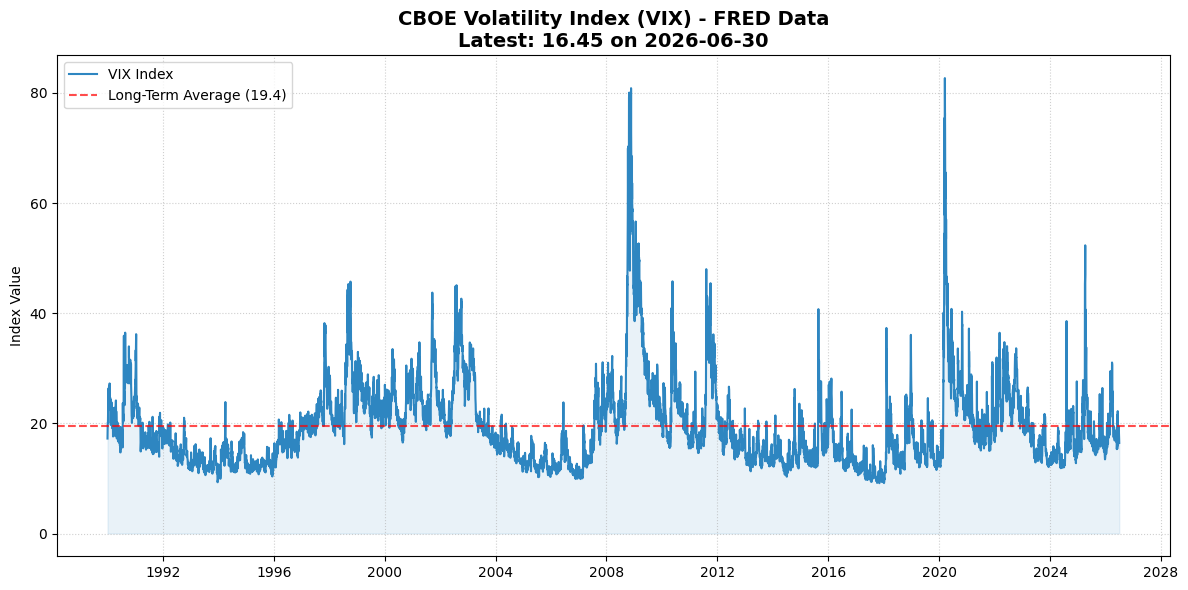

In [10]:
import pandas_datareader.data as web
import pandas as pd
import matplotlib.pyplot as plt
import datetime

def plot_vix_from_fred(end_date=datetime.datetime(2026, 6, 30)):
    # 1. Define the sample period (default end: 2026-06-30)
    start_date = datetime.datetime(1990, 1, 1)

    print(f"Fetching VIX data from FRED ({start_date.year} - {end_date.strftime('%Y-%m-%d')})...")

    try:
        # 2. Retrieve Data (Series ID: VIXCLS)
        vix_data = web.DataReader('VIXCLS', 'fred', start_date, end_date)
        
        # Drop NaN values (non-trading days)
        vix_data = vix_data.dropna()
        
        # Get the very latest value
        latest_date = vix_data.index[-1].strftime('%Y-%m-%d')
        latest_val = vix_data['VIXCLS'].iloc[-1]
        
        # 3. Visualization
        plt.figure(figsize=(12, 6))
        
        # Plot the main line
        plt.plot(vix_data.index, vix_data['VIXCLS'], color='#2E86C1', linewidth=1.5, label='VIX Index')
        
        # Add a horizontal line for the Long-Term Average
        long_term_avg = vix_data['VIXCLS'].mean()
        plt.axhline(long_term_avg, color='red', linestyle='--', alpha=0.7, 
                    label=f'Long-Term Average ({long_term_avg:.1f})')
        
        # Formatting
        plt.title(f'CBOE Volatility Index (VIX) - FRED Data\nLatest: {latest_val:.2f} on {latest_date}', 
                  fontsize=14, fontweight='bold')
        plt.ylabel('Index Value')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(loc='upper left')
        
        # Highlight recent period
        plt.fill_between(vix_data.index, vix_data['VIXCLS'], alpha=0.1, color='#2E86C1')

        plt.tight_layout()
        plt.show()
        

    except Exception as e:
        print(f"Error fetching data: {e}")
        print("Ensure you have an internet connection and 'pandas_datareader' installed.")

# Run the function
plot_vix_from_fred()

### Black-Scholes Option Pricing Model
$$ C_t = S_t\times\underbrace{N(d_1)}_{\Delta_C} - \underbrace{PV(K)N(d_2)}_{\text{Borrowing}} $$
$$ P_t = \underbrace{PV(K)[1-N(d_2)]}_{\text{Lending}} + \underbrace{[N(d_1)-1]}_{\Delta_P}\times S_t $$

* Option delta, $\Delta=\partial V/\partial S$, is the local slope of the option-value curve.
  
  * For a small stock-price change: $\text{Change in option value}\approx\Delta\times\text{Change in stock price}$.
  
  * For these European options: $0<\Delta_C<1$ and $-1<\Delta_P<0$. Calls rise and puts fall when the stock price rises, holding other inputs fixed.
  
  * When the stock price changes, $\Delta$ also changes.
  
  * The stock-and-cash portfolio is tangent to the option-value curve at the current stock price. Continuous rebalancing maintains replication under the model's assumptions.

---


In [11]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import ipywidgets as widgets
from IPython.display import display, HTML


def delta_replication_values(S, K, tau, r_pct, sigma_pct, option_type):
    """Black-Scholes value, delta and cash position for non-dividend-paying stock."""
    S=np.asarray(S,dtype=float)
    if not np.all(np.isfinite(S)) or not all(math.isfinite(x) for x in (K,tau,r_pct,sigma_pct)):
        raise ValueError('All numerical inputs must be finite.')
    if np.any(S<0) or min(K,tau,sigma_pct)<=0:
        raise ValueError('Use nonnegative stock prices and positive strike, time and volatility.')
    if option_type not in {'Call','Put'}:
        raise ValueError('Choose Call or Put.')
    r,sigma=r_pct/100,sigma_pct/100
    pv=K*math.exp(-r*tau)
    gap=sigma*math.sqrt(tau)
    d1=np.full_like(S,-np.inf)
    positive=S>0
    d1[positive]=(np.log(S[positive]/K)+(r+sigma*sigma/2)*tau)/gap
    d2=d1-gap
    if option_type=='Call':
        delta=norm.cdf(d1)
        cash=-pv*norm.cdf(d2)
        price=S*delta+cash
        intrinsic=np.maximum(S-K,0)
    else:
        delta=-norm.cdf(-d1)
        cash=pv*norm.cdf(-d2)
        price=S*delta+cash
        intrinsic=np.maximum(K-S,0)
    return dict(price=np.maximum(price,0),intrinsic=intrinsic,delta=delta,cash=cash,
                pv=pv,d1=d1,d2=d2)


def plot_delta_replication(S0, K, tau, r_pct, sigma_pct, option_type):
    if not math.isfinite(S0) or S0<=0:
        raise ValueError('Use a positive current stock price.')
    x=np.linspace(0,24,801)
    curve=delta_replication_values(x,K,tau,r_pct,sigma_pct,option_type)
    m=delta_replication_values(S0,K,tau,r_pct,sigma_pct,option_type)
    value,delta,cash=(float(m[key]) for key in ('price','delta','cash'))
    d1,d2=float(m['d1']),float(m['d2'])
    tangent=delta*x+cash
    symbol='C' if option_type=='Call' else 'P'
    ink,blue,orange='#172333','#005A9C','#A64B00'
    fig,(plot,calc)=plt.subplots(1,2,figsize=(16,8),gridspec_kw={'width_ratios':[1.10,1]})
    fig.subplots_adjust(left=0.065,right=0.98,top=0.80,bottom=0.18,wspace=0.19)
    fig.suptitle('Delta and the Replicating Portfolio',fontsize=20,color=ink,y=0.97)
    fig.text(0.5,0.90,
        f'European {option_type.lower()} | Stock: USD {S0:.2f} | Strike: USD {K:.2f} | '
        f'Time: {tau:g} years | Annual cc rate: {r_pct:g}% | Annual volatility: {sigma_pct:g}%',
        ha='center',fontsize=14,color=ink)
    plot.plot(x,curve['price'],color=blue,lw=2.5,label='Option value')
    plot.plot(x,curve['intrinsic'],color=ink,ls=':',lw=1.8,label='Intrinsic value')
    plot.plot(x,tangent,color=orange,ls='--',lw=2,label='Current stock-and-cash portfolio')
    plot.scatter([S0],[value],s=65,color=orange,edgecolors=ink,zorder=6,label='Current price and value')
    plot.vlines(S0,0,value,colors='#7A8794',linestyles=':',lw=1)
    plot.hlines(value,0,S0,colors='#7A8794',linestyles=':',lw=1)
    plot.axhline(0,color=ink,lw=0.8)
    # All selected stock prices and option values fit these unchanged axes.
    plot.set(xlim=(0,24),ylim=(-10,24),xlabel='Stock price (USD)',ylabel='Value (USD)')
    plot.set_xticks(np.arange(0,25,4))
    plot.set_yticks([-10,-5,0,5,10,15,20,24])
    plot.tick_params(labelsize=13)
    plot.xaxis.label.set_size(14); plot.yaxis.label.set_size(14)
    plot.spines[['top','right']].set_visible(False)
    plot.grid(True,ls=':',alpha=0.25)
    # Place the legend away from the high-value side of the curve.
    plot.legend(loc='upper left' if option_type=='Call' else 'upper right',fontsize=11,framealpha=0.95)
    if cash < -10:
        plot.annotate('Cash intercept below view',xy=(0.4,-9.9),xytext=(1,-7),
                      fontsize=11,color=orange,arrowprops=dict(arrowstyle='->',color=orange))

    calc.set(xlim=(0,1),ylim=(0,1)); calc.axis('off')
    if option_type=='Call':
        delta_line=rf'$\Delta=N(d_1)=N({d1:.4f})={delta:.4f}$'
        cash_line=rf'$B=-PV(K)N(d_2)={cash:.4f}$'
        position=f'Buy {delta:.4f} shares; borrow USD {-cash:.4f}.'
    else:
        delta_line=rf'$\Delta=N(d_1)-1=N({d1:.4f})-1={delta:.4f}$'
        cash_line=rf'$B=PV(K)[1-N(d_2)]={cash:.4f}$'
        position=f'Short {-delta:.4f} shares; lend USD {cash:.4f}.'
    rows=[
        (0.98,'1. Delta: Slope at the selected point',16),
        (0.86,delta_line,16),
        (0.71,'2. Stock and cash positions',16),
        (0.60,cash_line,16),
        (0.49,position,14),
        (0.35,'3. Match the option value today',16),
        (0.24,rf'${symbol}_0=\Delta S_0+B={delta:.4f}({S0:.2f})+({cash:.4f})$',16),
        (0.13,rf'${symbol}_0={value:.4f}$',18),
        (0.00,rf'Tangent: $V_{{\mathrm{{rep}}}}(S)={delta:.4f}S+({cash:.4f})$',15),
    ]
    for y,text,size in rows: calc.text(0.01,y,text,fontsize=size,color=ink,va='center')
    fig.text(0.5,0.06,'The fixed portfolio matches value and slope at the selected point. Rebalance as delta changes.',
             ha='center',fontsize=15,color=ink)
    plt.show()
    return fig


def make_delta_replication_demo():
    style={'description_width':'125px'}
    def slider(value,low,high,step,label):
        return widgets.FloatSlider(value=value,min=low,max=high,step=step,description=label,
            style=style,layout=widgets.Layout(width='100%'),continuous_update=False)
    controls={
        'option_type':widgets.Dropdown(options=['Call','Put'],value='Call',description='European option:',style=style),
        'r_pct':slider(4,0,20,0.5,'Annual cc rate (%):'),
        'S0':slider(12,0.5,20,0.5,'Stock (USD):'),
        'K':slider(13,1,20,0.5,'Strike (USD):'),
        'tau':slider(1,0.1,5,0.1,'Time (years):'),
        'sigma_pct':slider(25,5,100,1,'Annual vol. (%):'),
    }
    grid=widgets.GridBox(list(controls.values()),layout=widgets.Layout(
        grid_template_columns='repeat(2, minmax(300px, 1fr))',grid_gap='4px 20px',width='100%',max_width='900px'))
    def render(**values):
        try: plot_delta_replication(**values)
        except ValueError as error: display(HTML(f'<p style="font-size:16px;color:#A64B00">{error}</p>'))
    output=widgets.interactive_output(render,controls)
    return widgets.VBox([grid,output])


delta_replication_demo=make_delta_replication_demo()
display(delta_replication_demo)


### Black-Scholes Option Pricing Model

* Risk and Return of an Option

  * The replicating portfolio has option value $V=S_t\Delta+B$, where $B$ is the cash position.
$$ \beta_{Option} = \frac{S_t \Delta}{V} \beta_S + \frac{B}{V} \beta_B $$
$$ \text{Since } \beta_B = 0, \quad \beta_{Option} = \frac{S_t \Delta}{V} \beta_S $$
$$ \Omega = \frac{S_t \Delta}{V} \quad \text{is the option's signed leverage ratio.} $$

* For a stock with positive beta: calls have positive beta; puts have negative beta.

* Delta, leverage and option beta change as the stock price changes.

---


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.special import log_ndtr
import ipywidgets as widgets
from IPython.display import display


def option_risk_values(S, K, T, r_pct, sigma_pct, option_type):
    """European, non-dividend-paying option; stable even for very small prices."""
    S = np.asarray(S, dtype=float)
    r, sigma = r_pct / 100, sigma_pct / 100
    if (not np.all(np.isfinite(S)) or np.any(S <= 0)
            or not np.all(np.isfinite([K, T, r, sigma]))
            or K <= 0 or T <= 0 or sigma <= 0):
        raise ValueError('Stock, strike, time and volatility must be positive and finite.')
    d1 = (np.log(S / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == 'Call':
        log_a = np.log(S) + log_ndtr(d1)
        log_b = np.log(K) - r * T + log_ndtr(d2)
        delta = np.exp(log_ndtr(d1))
        sign = 1
    elif option_type == 'Put':
        log_a = np.log(K) - r * T + log_ndtr(-d2)
        log_b = np.log(S) + log_ndtr(-d1)
        delta = -np.exp(log_ndtr(-d1))
        sign = -1
    else:
        raise ValueError('Choose Call or Put.')
    # Price = A - B. expm1 avoids subtracting nearly equal rounded prices.
    gap = -np.expm1(log_b - log_a)
    if np.any(gap <= 0):
        raise ArithmeticError('Option price is beyond numerical precision.')
    log_price = log_a + np.log(gap)
    leverage = 1 / gap if sign == 1 else -np.exp(log_b - log_a) / gap
    return np.exp(log_price), delta, leverage, log_price


def plot_option_risk(S0, K, T, r_pct, sigma_pct, beta_s, erm_pct, option_type):
    r, erm = r_pct / 100, erm_pct / 100
    price, delta, omega, log_price = option_risk_values(S0, K, T, r_pct, sigma_pct, option_type)
    beta_option = float(omega * beta_s)
    stock_return = r + beta_s * (erm - r)
    option_return = r + beta_option * (erm - r)
    stocks = np.linspace(50, 180, 500)
    leverage = option_risk_values(stocks, K, T, r_pct, sigma_pct, option_type)[2]
    blue, orange = '#1764a0', '#c85a12'
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    fig.subplots_adjust(left=.07, right=.97, top=.89, bottom=.38, wspace=.27)
    fig.suptitle(f'{option_type}: Leverage, Beta and Expected Return', fontsize=20)

    ax1.plot(stocks, leverage, color=blue, lw=2.5)
    ax1.axhline(0, color='0.5', lw=.8)
    ax1.axvline(S0, color=orange, ls=':', lw=1.3)
    ax1.set(xlim=(50, 180), ylim=(-15, 15))
    ax1.set_title(r'Leverage: $\Omega=S\Delta/V$', fontsize=17, pad=12)
    ax1.set_xlabel('Stock price (USD)', fontsize=14)
    ax1.set_ylabel('Signed leverage', fontsize=14)
    if -15 <= omega <= 15:
        ax1.plot(S0, omega, 'o', color=orange, ms=9)
    else:
        ax1.annotate('', xy=(S0, np.sign(omega)*14.8),
                     xytext=(S0, np.sign(omega)*11.5),
                     arrowprops=dict(arrowstyle='->', color=orange, lw=2))
    ax1.text(.03, .95, rf'Current $\Omega={omega:,.2f}$'
             + (' (outside view)' if abs(omega) > 15 else ''),
             transform=ax1.transAxes, va='top', fontsize=14,
             bbox=dict(facecolor='white', edgecolor='none', alpha=.9))

    betas = np.linspace(-10, 10, 200)
    ax2.plot(betas, r + betas*(erm-r), '--', color='0.4', lw=2, label='SML')
    ax2.axhline(0, color='0.5', lw=.8)
    ax2.axvline(0, color='0.5', lw=.8)
    ax2.plot(0, r, 'o', color='#367448', ms=7, label='Risk-free')
    ax2.plot(beta_s, stock_return, 's', color=blue, ms=8, label='Stock')
    in_view = -10 <= beta_option <= 10 and -1.1 <= option_return <= 1.1
    if in_view:
        ax2.plot(beta_option, option_return, 'o', color=orange, ms=10, label=option_type)
    else:
        # Place an arrow at the SML's intersection with the fixed view boundary.
        scale = min(9.8 / abs(beta_option),
                    1.06 / max(abs(option_return - r), 1e-12))
        edge_beta = beta_option * scale
        edge_return = r + edge_beta*(erm-r)
        if abs(edge_return) > 1.08:
            edge_return = np.copysign(1.08, edge_return)
            edge_beta = (edge_return-r)/(erm-r)
        ax2.annotate('', xy=(edge_beta, edge_return),
                     xytext=(edge_beta*.82, r + edge_beta*.82*(erm-r)),
                     arrowprops=dict(arrowstyle='->', color=orange, lw=2))
        ax2.plot([], [], 'o', color=orange, label=f'{option_type} outside view')
    ax2.set(xlim=(-10, 10), ylim=(-1.1, 1.1))
    ax2.set_title('Expected Return and Systematic Risk', fontsize=17, pad=12)
    ax2.set_xlabel(r'Beta ($\beta$)', fontsize=14)
    ax2.set_ylabel('Expected return (annualized)', fontsize=14)
    ax2.yaxis.set_major_formatter(PercentFormatter(1))
    ax2.legend(loc='upper left', fontsize=12, framealpha=.95, ncol=2)
    for ax in (ax1, ax2):
        ax.tick_params(labelsize=12)
        ax.grid(alpha=.2)

    # Scientific notation keeps small option values visible rather than rounding to zero.
    if price >= .01:
        price_text = f'{price:,.4f}'
    else:
        exponent = int(np.floor(float(log_price) / np.log(10)))
        mantissa = np.exp(float(log_price) - exponent*np.log(10))
        price_text = f'{mantissa:.3f}e{exponent:+d}'
    fig.text(.07, .27, rf'$V=${price_text} USD     $\Delta={delta:.4g}$', fontsize=16)
    fig.text(.07, .20, rf'$\Omega=S\Delta/V={omega:,.2f}$', fontsize=17, color=blue)
    fig.text(.53, .27, rf'$\beta_{{option}}=\Omega\beta_S={omega:,.2f}\times {beta_s:.2f}={beta_option:,.2f}$', fontsize=16)
    fig.text(.53, .20, rf'$\mu_{{option}}=r+\beta_{{option}}(\mu_M-r)=$ {option_return:.2%}', fontsize=16, color=orange)
    fig.text(.07, .11, 'European options on a non-dividend-paying stock. Both graph scales stay fixed.', fontsize=13)
    fig.text(.07, .06, 'CAPM returns are instantaneous rates, annualized; leverage and beta change as the stock price changes.', fontsize=13)
    plt.show()


def make_option_risk_demo():
    style = {'description_width': '125px'}
    layout = widgets.Layout(width='420px')
    controls = {'option_type': widgets.Dropdown(options=['Call', 'Put'], value='Call',
                  description='Option:', style=style, layout=layout)}
    specifications = [
        ('S0', 'Stock (USD):', 100, 50, 180, 1),
        ('K', 'Strike (USD):', 100, 50, 180, 5),
        ('T', 'Time (years):', 1, .1, 5, .1),
        ('r_pct', 'Risk-free (cc %):', 5, 0, 10, .5),
        ('sigma_pct', 'Volatility (%):', 30, 10, 100, 5),
        ('beta_s', 'Stock beta:', 1, .5, 2, .1),
        ('erm_pct', 'Market return (%):', 10, 5, 20, .5)]
    for key, label, value, low, high, step in specifications:
        controls[key] = widgets.FloatSlider(value=value, min=low, max=high, step=step,
            description=label, style=style, layout=layout, continuous_update=False)
    output = widgets.interactive_output(plot_option_risk, controls)
    grid = widgets.GridBox(list(controls.values()),
                           layout=widgets.Layout(grid_template_columns='repeat(2, 430px)'))
    return widgets.VBox([grid, output])


option_risk_demo = make_option_risk_demo()
display(option_risk_demo)


### Black-Scholes Option Pricing Model

* Lambda stock pays no dividends. Its current price is $90 and annual volatility is 30%.

* The continuously compounded risk-free rate is 6% per year. Find the value of a six-month, at-the-money European call.

$$ C_t = S_t N(d_1) - PV(K)N(d_2) $$

* Calculate $d_1$ and $d_2$, with $K=90$ and $T=0.5$:

$$ d_1 = \frac{\ln(S_t/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}}
= \frac{\ln(90/90)+(0.06+0.30^2/2)\times0.5}{0.30\sqrt{0.5}}
= \frac{0.0525}{0.30\sqrt{0.5}} \approx 0.2475 $$
$$ N(d_1) \approx 0.597734 $$

$$ d_2 = d_1-\sigma\sqrt{T} = d_1-0.30\sqrt{0.5} \approx 0.0354 $$
$$ N(d_2) \approx 0.514102 $$

* Calculate the call price:

$$ PV(K)=90e^{-0.06\times0.5}\approx87.3401 $$
$$ C_t=90N(d_1)-90e^{-0.06\times0.5}N(d_2)
\approx53.7961-44.9017=8.8944\approx\$8.89 $$

---


### Black-Scholes Option Pricing Model

Suppose the Lambda call is unavailable for trade. What portfolio should you hold today to replicate a long position in one call?

$$ C_t = \underbrace{S_t N(d_1)}_{\text{Stock Position}} + \underbrace{B}_{\text{Cash Position}},
\qquad B=-PV(K)N(d_2) $$

1. Buy $\Delta=N(d_1)\approx0.597734$ shares.
   $$ \text{Stock cost}=90N(d_1)\approx\$53.7961 $$

2. Borrow $PV(K)N(d_2)$ at the risk-free rate.
   $$ B=-90e^{-0.06\times0.5}N(d_2)\approx-\$44.9017 $$

* Net cost:
  $$ C_t=S_t\Delta+B\approx53.7961-44.9017=8.8944\approx\$8.89 $$
* Continuously rebalance the stock and cash positions as delta changes to maintain replication.

---


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.special import log_ndtr
import ipywidgets as widgets
from IPython.display import display


def lambda_call_values(S, K, T, r_pct, sigma_pct):
    """BSM call and signed replicating positions; no dividends."""
    r, sigma = r_pct / 100, sigma_pct / 100
    if (not np.all(np.isfinite([S, K, T, r, sigma]))
            or min(S, K, T, sigma) <= 0):
        raise ValueError('Stock, strike, time and volatility must be positive and finite.')
    log_sk = np.log(S / K)
    drift = (r + sigma**2 / 2) * T
    vol_time = sigma * np.sqrt(T)
    d1 = (log_sk + drift) / vol_time
    d2 = d1 - vol_time
    n1, n2 = norm.cdf(d1), norm.cdf(d2)
    pv_k = K * np.exp(-r * T)
    stock, cash = S * n1, -pv_k * n2
    # Stable difference for small call values, rather than cancelling rounded positions.
    log_stock = np.log(S) + log_ndtr(d1)
    log_loan = np.log(K) - r*T + log_ndtr(d2)
    gap = -np.expm1(log_loan - log_stock)
    if gap <= 0:
        raise ArithmeticError('Call value is beyond numerical precision.')
    log_call = log_stock + np.log(gap)
    return dict(d1=d1, d2=d2, n1=n1, n2=n2, pv_k=pv_k,
                stock=stock, cash=cash, call=np.exp(log_call), log_call=log_call,
                log_sk=log_sk, drift=drift, vol_time=vol_time)


def plot_lambda_call(S, K, T, r_pct, sigma_pct):
    m = lambda_call_values(S, K, T, r_pct, sigma_pct)
    blue, orange = '#1764a0', '#c85a12'
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 9))
    fig.subplots_adjust(left=.07, right=.97, top=.88, bottom=.43, wspace=.25)
    fig.suptitle('Lambda: Call Value and Replicating Portfolio', fontsize=20)
    x = np.linspace(-4, 4, 1200)
    density = norm.pdf(x)
    ax1.plot(x, density, color='0.4', lw=1.8)
    ax1.fill_between(x, density, where=x <= m['d2'], interpolate=True,
                     color=orange, alpha=.22)
    for key, color, style in [('d1', blue, '-'), ('d2', orange, '--')]:
        d, cdf = m[key], m['n'+key[-1]]
        label = rf'${key[0]}_{key[1]}={d:.4f}$; $N({key[0]}_{key[1]})={cdf:.4f}$'
        if -4 <= d <= 4:
            ax1.axvline(d, color=color, ls=style, lw=2, label=label)
        else:
            ax1.plot([], [], color=color, ls=style, lw=2, label=label+' (outside view)')
            y = .09 if key == 'd1' else .05
            ax1.annotate('', xy=(np.sign(d)*3.95, y), xytext=(np.sign(d)*3.4, y),
                         arrowprops=dict(arrowstyle='->', color=color, lw=2))
    ax1.set(xlim=(-4, 4), ylim=(0, .5))
    ax1.set_title('Standard Normal Distribution', fontsize=17, pad=12)
    ax1.set_xlabel('Standard normal value', fontsize=14)
    ax1.set_ylabel('Probability density', fontsize=14)
    ax1.legend(loc='upper left', fontsize=12, framealpha=.95)

    values = [m['stock'], m['cash'], m['call']]
    bars = ax2.bar(['Stock\n'+r'$S\Delta$', 'Cash\n'+r'$B$', 'Call\n'+r'$C=S\Delta+B$'],
                   values, color=[blue, orange, '#367448'], width=.62)
    for bar, value in zip(bars, values):
        label = f'{value:,.2f}'
        if 0 < value < .01:
            label = '<0.01'
        elif value == 0 and bar is bars[-1]:
            label = '<0.01'
        ax2.annotate(label, xy=(bar.get_x()+bar.get_width()/2, value),
                     xytext=(0, 7 if value >= 0 else -7), textcoords='offset points',
                     ha='center', va='bottom' if value >= 0 else 'top', fontsize=14)
    ax2.axhline(0, color='0.4', lw=1)
    ax2.set_ylim(-135, 135)
    ax2.set_title('Replicating Positions Today', fontsize=17, pad=12)
    ax2.set_ylabel('Value (USD)', fontsize=14)
    for ax in (ax1, ax2):
        ax.tick_params(labelsize=12)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)

    fig.text(.07, .34, 'Calculate the Call', fontsize=17, color=blue)
    fig.text(.07, .285, rf'$d_1=({m["log_sk"]:.4f}+{m["drift"]:.4f})/{m["vol_time"]:.4f}={m["d1"]:.4f}$', fontsize=16)
    fig.text(.07, .23, rf'$d_2=d_1-\sigma\sqrt{{T}}={m["d2"]:.4f}$', fontsize=16)
    fig.text(.07, .175, rf'$PV(K)={K:g}e^{{-({r_pct/100:g})({T:g})}}={m["pv_k"]:.4f}$', fontsize=16)
    if m['call'] >= .0001:
        call_text = f'{m["call"]:.4f}'
    else:
        exponent = int(np.floor(m['log_call']/np.log(10)))
        mantissa = np.exp(m['log_call']-exponent*np.log(10))
        call_text = f'{mantissa:.3f}e{exponent:+d}'
    fig.text(.54, .34, 'Replicate the Call', fontsize=17, color=orange)
    fig.text(.54, .285, rf'Buy $\Delta=N(d_1)={m["n1"]:.6f}$ shares', fontsize=16)
    fig.text(.54, .23, rf'$B=-PV(K)N(d_2)={m["cash"]:.4f}$ USD', fontsize=16)
    fig.text(.54, .175, rf'$C=S\Delta+B=$ {call_text} USD', fontsize=16)
    fig.text(.07, .09, r'$N(d_2)$: risk-neutral probability of finishing in the money. $N(d_1)$: call delta.', fontsize=13)
    fig.text(.07, .045, 'Rebalance as delta changes. Calculations use full precision; displayed intermediate values are rounded.', fontsize=13)
    plt.show()


def make_lambda_call_demo():
    style = {'description_width': '125px'}
    specifications = [
        ('S', 'Stock (USD):', 90, 40, 120, 1),
        ('K', 'Strike (USD):', 90, 40, 120, 1),
        ('T', 'Time (years):', .5, .1, 2, .1),
        ('r_pct', 'Risk-free (cc %):', 6, 0, 10, .5),
        ('sigma_pct', 'Volatility (%):', 30, 5, 100, 5)]
    controls = {key: widgets.FloatSlider(value=value, min=low, max=high, step=step,
                    description=label, style=style, layout=widgets.Layout(width='420px'),
                    continuous_update=False)
                for key, label, value, low, high, step in specifications}
    output = widgets.interactive_output(plot_lambda_call, controls)
    grid = widgets.GridBox(list(controls.values()),
                           layout=widgets.Layout(grid_template_columns='repeat(2, 430px)'))
    return widgets.VBox([grid, output])


lambda_call_demo = make_lambda_call_demo()
display(lambda_call_demo)


### Black-Scholes Option Pricing Model

* Theta is considering a European call on Sigma stock, which pays no dividends. The stock price is $120, the strike is $125, and the option expires in nine months.

* Annual volatility is 28%, and the continuously compounded risk-free rate is 4% per year.

* Using the Black-Scholes formula, compute the call price.

$$ d_1=\frac{\ln(120/125)+(0.04+0.5(0.28)^2)\times0.75}{0.28\sqrt{0.75}} $$
$$ d_1\approx\frac{-0.040822+0.059400}{0.242487}\approx0.0766,
\qquad N(d_1)\approx0.530535 $$

$$ d_2=d_1-0.28\sqrt{0.75}\approx-0.1659,
\qquad N(d_2)\approx0.434129 $$

$$ C_t=S_tN(d_1)-Ke^{-rT}N(d_2) $$
$$ C_t=120N(d_1)-125e^{-0.04\times0.75}N(d_2) $$
$$ C_t\approx63.6642-52.6623=11.0019\approx\$11.00 $$

* Use put-call parity to compute the price of the European put with the same strike and expiration date.

$$ P_t=C_t-S_t+Ke^{-rT} $$
$$ P_t=C_t-120+125e^{-0.04\times0.75} $$
$$ P_t\approx11.0019-120+121.3057=12.3076\approx\$12.31 $$

---


### What is next?

*   Recitation Session(s)

*   Final Exam: 12 November 2026
    
*   Suggested Problems
        *   Chapter 20: 6, 7, 8, 10, 20, 30

---
